In [ ]:
pip install chembl_webresource_client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.8/70.8 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 3.5 MB/s eta 0:00:00


In [ ]:
from chembl_webresource_client.new_client import new_client
import pandas as pd

In [ ]:
target = new_client.target

# Busca os dois alvos
query_tgr = target.search('thioredoxin glutathione reductase Schistosoma mansoni')
query_hdac8 = target.search('histone deacetylase 8 Schistosoma mansoni')

df_tgr = pd.DataFrame.from_dict(query_tgr)
df_hdac8 = pd.DataFrame.from_dict(query_hdac8)

print("=== Resultados TGR ===")
print(df_tgr[['target_chembl_id', 'pref_name', 'organism', 'target_type']])

print("\n=== Resultados smHDAC8 ===")
print(df_hdac8[['target_chembl_id', 'pref_name', 'organism', 'target_type']])

=== Resultados TGR ===
    target_chembl_id                                          pref_name  \
0       CHEMBL612893                                Schistosoma mansoni   
1         CHEMBL3793                            Thioredoxin reductase 3   
2         CHEMBL6110                  Thioredoxin glutathione reductase   
3      CHEMBL2096978                              Thioredoxin reductase   
4      CHEMBL4523369                  Thioredoxin glutathione reductase   
..               ...                                                ...   
972    CHEMBL3885503  5'-AMP-activated protein kinase catalytic subu...   
973    CHEMBL2364675                                 Cytochrome P450 3A   
974    CHEMBL3712956                                     STEAP1 protein   
975    CHEMBL4106157               GABA-A receptor alpha-4/beta-3/delta   
976    CHEMBL4523986                                    Cytochrome P450   

                    organism      target_type  
0        Schistosoma mansoni

In [ ]:
# Substitua pelos IDs reais que você confirmar na etapa 1
TGR_ID = 'CHEEMMBL6110'
HDAC8_ID = 'CHBL3797017'

targets_dict = {
    ''TGR: TGR_ID,
    'smHDAC8': HDAC8_ID
}

print(targets_dict)

{'TGR': 'CHEMBL6110', 'smHDAC8': 'CHEMBL3797017'}


In [ ]:
import os

os.makedirs('data/TGR', exist_ok=True)
os.makedirs('data/smHDAC8', exist_ok=True)

activity = new_client.activity
datasets = {}

for nome, chembl_id in targets_dict.items():
    print(f"Buscando atividades para {nome} ({chembl_id})...")

    res = activity.filter(
        target_chembl_id=chembl_id
    ).filter(
        standard_type__in=["IC50", "EC50", "Ki"]
    )

    df = pd.DataFrame.from_dict(res)
    df['target_group'] = nome

    datasets[nome] = df
    df.to_csv(f'data/{nome}/{nome}_raw_activities.csv', index=False)
    print(f"  -> {len(df)} registros salvos\n")

Buscando atividades para TGR (CHEMBL6110)...
  -> 59 registros salvos

Buscando atividades para smHDAC8 (CHEMBL3797017)...
  -> 260 registros salvos



# Quantos compostos únicos tenho de fato em cada alvo (às vezes o mesmo composto aparece em múltiplos ensaios, o que infla a contagem de "registros" mas não de compostos reais para o modelo).

In [ ]:
for nome, df in datasets.items():
    print(f"=== {nome} ===")
    print(f"Total: {len(df)}")
    print(f"Compostos únicos: {df['molecule_chembl_id'].nunique()}")
    print(f"Tipos de ensaio: {df['standard_type'].value_counts().to_dict()}")
    print(f"Unidades: {df['standard_units'].value_counts().to_dict()}")
    print(f"Valores nulos em standard_value: {df['standard_value'].isna().sum()}")
    print()

=== TGR ===
Total: 59
Compostos únicos: 58
Tipos de ensaio: {'IC50': 59}
Unidades: {'nM': 58}
Valores nulos em standard_value: 1

=== smHDAC8 ===
Total: 260
Compostos únicos: 216
Tipos de ensaio: {'IC50': 260}
Unidades: {'nM': 258}
Valores nulos em standard_value: 2



# Próxima etapa: limpeza e padronização

In [ ]:
def clean_activity_data(df, nome):
    print(f"--- Limpando {nome} ---")
    print(f"Antes: {len(df)} registros")

    # Remove nulos em standard_value
    df = df.dropna(subset=['standard_value'])

    # Garante que só ficou nM (já é quase 100%, mas por segurança)
    df = df[df['standard_units'] == 'nM']

    # Converte standard_value pra numérico
    df['standard_value'] = pd.to_numeric(df['standard_value'], errors='coerce')
    df = df.dropna(subset=['standard_value'])

    # Remove valores <= 0 (não fazem sentido biologicamente, log vai quebrar)
    df = df[df['standard_value'] > 0]

    # Trata duplicatas: agrupa por composto e tira a MEDIANA do IC50
    # (mediana é mais robusta a outliers que a média)
    df_dedup = (
        df.groupby('molecule_chembl_id')
        .agg({
            'standard_value': 'median',
            'canonical_smiles': 'first',
            'target_group': 'first'
        })
        .reset_index()
    )

    print(f"Depois (deduplicado): {len(df_dedup)} compostos únicos\n")
    return df_dedup

tgr_clean = clean_activity_data(datasets['TGR'], 'TGR')
hdac8_clean = clean_activity_data(datasets['smHDAC8'], 'smHDAC8')

--- Limpando TGR ---
Antes: 59 registros
Depois (deduplicado): 57 compostos únicos

--- Limpando smHDAC8 ---
Antes: 260 registros
Depois (deduplicado): 214 compostos únicos



# Depois, calcular pIC50 (padrão em QSAR, converte pra escala logarítmica)

In [ ]:
import numpy as np

def add_pic50(df):
    # IC50 em nM -> converte pra M -> -log10 = pIC50
    df['pIC50'] = -np.log10(df['standard_value'] * 1e-9)
    return df

tgr_clean = add_pic50(tgr_clean)
hdac8_clean = add_pic50(hdac8_clean)

print(tgr_clean[['molecule_chembl_id', 'standard_value', 'pIC50']].describe())
print()
print(hdac8_clean[['molecule_chembl_id', 'standard_value', 'pIC50']].describe())

       standard_value      pIC50
count       57.000000  57.000000
mean     10925.964912   5.628526
std      16986.242590   0.950775
min         10.000000   4.240332
25%        350.000000   5.000000
50%       3500.000000   5.455932
75%      10000.000000   6.455932
max      57500.000000   8.000000

       standard_value       pIC50
count      214.000000  214.000000
mean     16262.637593    5.376346
std      14535.081184    0.973935
min         67.305000    4.300000
25%        400.000000    4.522879
50%      29545.000000    4.529568
75%      30000.000000    6.397940
max      50118.720000    7.171953


# Salvar os datasets limpos

In [ ]:
tgr_clean.to_csv('data/TGR/TGR_clean_pIC50.csv', index=False)
hdac8_clean.to_csv('data/smHDAC8/smHDAC8_clean_pIC50.csv', index=False)

print("Salvo com sucesso!")
print(f"TGR: {len(tgr_clean)} compostos prontos para descritores QSAR")
print(f"smHDAC8: {len(hdac8_clean)} compostos prontos para descritores QSAR")

Salvo com sucesso!
TGR: 57 compostos prontos para descritores QSAR
smHDAC8: 214 compostos prontos para descritores QSAR


# cálculo dos descritores moleculares (QSAR-3D)

Seguindo a mesma estrutura que já usei antes no meu pipeline (Lipinski, Morgan/ECFP4, MACCS Keys), agora farei isso para os dois alvos, mantendo tudo separado:

instal drkit

In [ ]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 20.6 MB/s eta 0:00:00


In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, AllChem, MACCSkeys
import numpy as np
import pandas as pd

print("RDKit importado com sucesso!")

RDKit importado com sucesso!


In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, AllChem, MACCSkeys
import numpy as np
import pandas as pd

def calc_lipinski(df, smiles_col='canonical_smiles'):
    rows = []
    for smi in df[smiles_col]:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            rows.append([None]*5)
            continue
        rows.append([
            Descriptors.MolWt(mol),
            Descriptors.MolLogP(mol),
            Lipinski.NumHDonors(mol),
            Lipinski.NumHAcceptors(mol),
            Descriptors.TPSA(mol)
        ])
    return pd.DataFrame(rows, columns=['MW', 'LogP', 'HBD', 'HBA', 'TPSA'])


def calc_ecfp4(df, smiles_col='canonical_smiles', n_bits=2048):
    fps = []
    for smi in df[smiles_col]:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            fps.append([0]*n_bits)
            continue
        fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=n_bits)
        fps.append(list(fp))
    cols = [f'ECFP4_{i}' for i in range(n_bits)]
    return pd.DataFrame(fps, columns=cols)


def calc_maccs(df, smiles_col='canonical_smiles'):
    fps = []
    for smi in df[smiles_col]:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            fps.append([0]*167)
            continue
        fp = MACCSkeys.GenMACCSKeys(mol)
        fps.append(list(fp))
    cols = [f'MACCS_{i}' for i in range(167)]
    return pd.DataFrame(fps, columns=cols)


def build_qsar_dataset(df, nome):
    print(f"Calculando descritores para {nome}...")

    lipinski = calc_lipinski(df)
    ecfp4 = calc_ecfp4(df)
    maccs = calc_maccs(df)

    base = df[['molecule_chembl_id', 'canonical_smiles', 'pIC50']].reset_index(drop=True)

    full_df = pd.concat([base, lipinski, ecfp4, maccs], axis=1)

    # Remove linhas onde o SMILES não pôde ser parseado (mol=None gerou tudo zero/None)
    full_df = full_df.dropna(subset=['MW'])

    print(f"  -> {len(full_df)} compostos com descritores calculados")
    print(f"  -> {full_df.shape[1]} colunas totais (descritores + fingerprints)\n")

    return full_df

In [ ]:
tgr_qsar = build_qsar_dataset(tgr_clean, 'TGR')
hdac8_qsar = build_qsar_dataset(hdac8_clean, 'smHDAC8')

tgr_qsar.to_csv('data/TGR/TGR_qsar_dataset.csv', index=False)
hdac8_qsar.to_csv('data/smHDAC8/smHDAC8_qsar_dataset.csv', index=False)

print("Datasets QSAR salvos com sucesso!")

Calculando descritores para TGR...


[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:09] DEPRECATION WARNING: please use MorganGenerat

  -> 57 compostos com descritores calculados
  -> 2223 colunas totais (descritores + fingerprints)

Calculando descritores para smHDAC8...


[01:56:09] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerator
[01:56:10] DEPRECATION WARNING: please use MorganGenerat

  -> 214 compostos com descritores calculados
  -> 2223 colunas totais (descritores + fingerprints)

Datasets QSAR salvos com sucesso!


In [ ]:
print(tgr_qsar.columns.tolist()[:10])
print(hdac8_qsar.columns.tolist()[:10])

['molecule_chembl_id', 'canonical_smiles', 'pIC50', 'MW', 'LogP', 'HBD', 'HBA', 'TPSA', 'ECFP4_0', 'ECFP4_1']
['molecule_chembl_id', 'canonical_smiles', 'pIC50', 'MW', 'LogP', 'HBD', 'HBA', 'TPSA', 'ECFP4_0', 'ECFP4_1']


In [ ]:
import os

for root, dirs, files in os.walk('data'):
    for f in files:
        print(os.path.join(root, f))

data/TGR/TGR_clean_pIC50.csv
data/TGR/TGR_raw_activities.csv
data/TGR/TGR_qsar_dataset.csv
data/smHDAC8/smHDAC8_clean_pIC50.csv
data/smHDAC8/smHDAC8_raw_activities.csv
data/smHDAC8/smHDAC8_qsar_dataset.csv


In [ ]:
tgr_checkpoint = pd.read_csv('data/TGR/TGR_clean_pIC50.csv')
hdac8_checkpoint = pd.read_csv('data/smHDAC8/smHDAC8_clean_pIC50.csv')

print(tgr_checkpoint.columns.tolist())

['molecule_chembl_id', 'standard_value', 'canonical_smiles', 'target_group', 'pIC50']


In [ ]:
tgr_checkpoint = pd.read_csv('data/TGR/TGR_clean_pIC50.csv')
hdac8_checkpoint = pd.read_csv('data/smHDAC8/smHDAC8_clean_pIC50.csv')

# Traz o standard_value de volta via merge pelo ID do composto
tgr_qsar = tgr_qsar.merge(
    tgr_checkpoint[['molecule_chembl_id', 'standard_value']],
    on='molecule_chembl_id',
    how='left'
)

hdac8_qsar = hdac8_qsar.merge(
    hdac8_checkpoint[['molecule_chembl_id', 'standard_value']],
    on='molecule_chembl_id',
    how='left'
)

print(tgr_qsar['standard_value'].isna().sum(), "valores faltando em TGR")
print(hdac8_qsar['standard_value'].isna().sum(), "valores faltando em smHDAC8")

0 valores faltando em TGR
0 valores faltando em smHDAC8


In [ ]:
def categorize_activity(ic50_nm):
    if ic50_nm < 100:
        return 'active'
    elif ic50_nm <= 1000:
        return 'intermediate'
    else:
        return 'inactive'

tgr_qsar['activity_class'] = tgr_qsar['standard_value'].apply(categorize_activity)
hdac8_qsar['activity_class'] = hdac8_qsar['standard_value'].apply(categorize_activity)

print("=== TGR ===")
print(tgr_qsar['activity_class'].value_counts())
print("\n=== smHDAC8 ===")
print(hdac8_qsar['activity_class'].value_counts())

=== TGR ===
activity_class
inactive        38
intermediate    14
active           5
Name: count, dtype: int64

=== smHDAC8 ===
activity_class
inactive        139
intermediate     69
active            6
Name: count, dtype: int64


# Passo 2 — pré-tratamento de descritores

In [ ]:
from sklearn.feature_selection import VarianceThreshold
import numpy as np

def pretreat_descriptors(df, feature_cols, var_threshold=0.01, corr_threshold=0.95):
    X = df[feature_cols].copy()

    selector = VarianceThreshold(threshold=var_threshold)
    selector.fit(X)
    X = X[X.columns[selector.get_support()]]
    print(f"Após filtro de variância: {X.shape[1]} colunas")

    corr_matrix = X.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [c for c in upper.columns if any(upper[c] > corr_threshold)]
    X = X.drop(columns=to_drop)
    print(f"Após filtro de correlação: {X.shape[1]} colunas")

    return X.columns.tolist()

id_cols = ['molecule_chembl_id', 'smiles_std', 'canonical_smiles', 'pIC50', 'standard_value', 'activity_class']

tgr_feature_cols_raw = [c for c in tgr_qsar.columns if c not in id_cols]
hdac8_feature_cols_raw = [c for c in hdac8_qsar.columns if c not in id_cols]

print("--- TGR ---")
tgr_features = pretreat_descriptors(tgr_qsar, tgr_feature_cols_raw)

print("\n--- smHDAC8 ---")
hdac8_features = pretreat_descriptors(hdac8_qsar, hdac8_feature_cols_raw)

--- TGR ---
Após filtro de variância: 654 colunas
Após filtro de correlação: 261 colunas

--- smHDAC8 ---
Após filtro de variância: 527 colunas
Após filtro de correlação: 398 colunas


# Passo 3 — split treino/teste via Kennard-Stone

In [ ]:
!pip install kennard-stone --quiet

In [ ]:
from kennard_stone import train_test_split as ks_split
import numpy as np

def kennard_stone_split(df, feature_cols, test_size=0.2):
    X = df[feature_cols].values
    idx = np.arange(len(df))

    X_train, X_test, idx_train, idx_test = ks_split(X, idx, test_size=test_size)

    return df.iloc[idx_train].reset_index(drop=True), df.iloc[idx_test].reset_index(drop=True)

tgr_train, tgr_test = kennard_stone_split(tgr_qsar, tgr_features, test_size=0.2)
hdac8_train, hdac8_test = kennard_stone_split(hdac8_qsar, hdac8_features, test_size=0.2)

print(f"TGR: {len(tgr_train)} treino / {len(tgr_test)} teste")
print(f"smHDAC8: {len(hdac8_train)} treino / {len(hdac8_test)} teste")

2026-08-19 01:56:28,127 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.

2026-08-19 01:56:28,157 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.

2026-08-19 01:56:28,247 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.

2026-08-19 01:56:28,275 - kennard_stone.utils._pairwise:114[INFO] - Calculating pairwise distances using scikit-learn.



TGR: 45 treino / 12 teste
smHDAC8: 171 treino / 43 teste


In [ ]:
tgr_train.to_csv('data/TGR/TGR_train.csv', index=False)
tgr_test.to_csv('data/TGR/TGR_test.csv', index=False)
hdac8_train.to_csv('data/smHDAC8/smHDAC8_train.csv', index=False)
hdac8_test.to_csv('data/smHDAC8/smHDAC8_test.csv', index=False)
print("Splits salvos!")

Splits salvos!


# Fase 5 — treinamento dos modelos,

# Passo 4 — Treinamento base com 10-fold CV (antes de otimizar)

In [ ]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score, KFold

def train_and_validate(X_train, y_train, nome):
    models = {
        'RandomForest': RandomForestRegressor(n_estimators=500, random_state=42),
        'HistGB': HistGradientBoostingRegressor(random_state=42)
    }
    kf = KFold(n_splits=10, shuffle=True, random_state=42)
    results = {}
    for model_name, model in models.items():
        scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')
        results[model_name] = scores
        print(f"{nome} - {model_name}: R² CV(10-fold) = {scores.mean():.3f} ± {scores.std():.3f}")
    return results

print(f"TGR treino: {tgr_train.shape[0]} compostos, {len(tgr_features)} features")
print(f"smHDAC8 treino: {hdac8_train.shape[0]} compostos, {len(hdac8_features)} features\n")

print("=== TGR ===")
tgr_baseline = train_and_validate(tgr_train[tgr_features], tgr_train['pIC50'], 'TGR')

print("\n=== smHDAC8 ===")
hdac8_baseline = train_and_validate(hdac8_train[hdac8_features], hdac8_train['pIC50'], 'smHDAC8')

TGR treino: 45 compostos, 261 features
smHDAC8 treino: 171 compostos, 398 features

=== TGR ===
TGR - RandomForest: R² CV(10-fold) = -0.082 ± 0.777
TGR - HistGB: R² CV(10-fold) = -0.763 ± 1.135

=== smHDAC8 ===
smHDAC8 - RandomForest: R² CV(10-fold) = 0.844 ± 0.101
smHDAC8 - HistGB: R² CV(10-fold) = 0.799 ± 0.141


# tgr tmlc kkkk mas ok, vamos tentar 3 correções,
# 1. Redução mais agressiva de features kkk (seleção supervisionada, só no TGR)

In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression

def select_top_k_features(X_train, y_train, feature_names, k=30):
    selector = SelectKBest(score_func=f_regression, k=min(k, X_train.shape[1]))
    selector.fit(X_train, y_train)
    selected = [f for f, s in zip(feature_names, selector.get_support()) if s]
    return selected

tgr_features_reduced = select_top_k_features(
    tgr_train[tgr_features], tgr_train['pIC50'], tgr_features, k=30
)
print(f"TGR reduzido para {len(tgr_features_reduced)} features")

TGR reduzido para 30 features


# 2. Adicionar PLS Regression e Ridge (padrão-ouro em QSAR com poucas amostras)

In [ ]:
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneOut, cross_val_score

def train_and_validate_v2(X_train, y_train, nome, cv_strategy):
    models = {
        'RandomForest_regularizado': RandomForestRegressor(
            n_estimators=300, max_depth=5, min_samples_leaf=3, random_state=42
        ),
        'Ridge': Ridge(alpha=10.0),
        'PLS': PLSRegression(n_components=5)
    }
    results = {}
    for model_name, model in models.items():
        scores = cross_val_score(model, X_train, y_train, cv=cv_strategy, scoring='r2')
        results[model_name] = scores
        print(f"{nome} - {model_name}: R² CV = {scores.mean():.3f} ± {scores.std():.3f}")
    return results

In [ ]:
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneOut, cross_val_score

def train_and_validate_v2(X_train, y_train, nome, cv_strategy):
    models = {
        'RandomForest_regularizado': RandomForestRegressor(
            n_estimators=300, max_depth=5, min_samples_leaf=3, random_state=42
        ),
        'Ridge': Ridge(alpha=10.0),
        'PLS': PLSRegression(n_components=5)
    }
    results = {}
    for model_name, model in models.items():
        scores = cross_val_score(model, X_train, y_train, cv=cv_strategy, scoring='r2')
        results[model_name] = scores
        print(f"{nome} - {model_name}: R² CV = {scores.mean():.3f} ± {scores.std():.3f}")
    return results

## 3. Leave-One-Out CV para o TGR (mais apropriado que 10-fold dado N pequeno)

In [ ]:
from sklearn.model_selection import cross_val_predict, LeaveOneOut
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.cross_decomposition import PLSRegression
import numpy as np

def train_and_validate_loo(X_train, y_train, nome):
    models = {
        'RandomForest_regularizado': RandomForestRegressor(
            n_estimators=300, max_depth=5, min_samples_leaf=3, random_state=42
        ),
        'Ridge': Ridge(alpha=10.0),
        'PLS': PLSRegression(n_components=5)
    }
    loo = LeaveOneOut()
    results = {}
    for model_name, model in models.items():
        y_pred = cross_val_predict(model, X_train, y_train, cv=loo)
        r2 = r2_score(y_train, y_pred)
        rmse = np.sqrt(mean_squared_error(y_train, y_pred))
        results[model_name] = {'r2': r2, 'rmse': rmse, 'y_pred': y_pred}
        print(f"{nome} - {model_name}: R² (LOO) = {r2:.3f}, RMSE = {rmse:.3f}")
    return results

print("=== TGR (features reduzidas, LOO-CV) ===")
tgr_results_v2 = train_and_validate_loo(
    tgr_train[tgr_features_reduced].values, tgr_train['pIC50'].values, 'TGR'
)

=== TGR (features reduzidas, LOO-CV) ===
TGR - RandomForest_regularizado: R² (LOO) = 0.369, RMSE = 0.808
TGR - Ridge: R² (LOO) = 0.423, RMSE = 0.773
TGR - PLS: R² (LOO) = 0.435, RMSE = 0.764


In [ ]:
from sklearn.model_selection import cross_val_predict, LeaveOneOut
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

loo = LeaveOneOut()
X_tgr = tgr_train[tgr_features_reduced].values
y_tgr = tgr_train['pIC50'].values

best_r2 = -np.inf
best_n = None

for n_comp in range(1, 15):
    model = PLSRegression(n_components=n_comp)
    y_pred = cross_val_predict(model, X_tgr, y_tgr, cv=loo)
    r2 = r2_score(y_tgr, y_pred)
    print(f"n_components={n_comp}: R² (LOO) = {r2:.3f}")
    if r2 > best_r2:
        best_r2 = r2
        best_n = n_comp

print(f"\nMelhor: n_components={best_n}, R² = {best_r2:.3f}")

n_components=1: R² (LOO) = 0.488
n_components=2: R² (LOO) = 0.508
n_components=3: R² (LOO) = 0.474
n_components=4: R² (LOO) = 0.451
n_components=5: R² (LOO) = 0.435
n_components=6: R² (LOO) = 0.410
n_components=7: R² (LOO) = 0.425
n_components=8: R² (LOO) = 0.407
n_components=9: R² (LOO) = 0.408
n_components=10: R² (LOO) = 0.394
n_components=11: R² (LOO) = 0.360
n_components=12: R² (LOO) = 0.317
n_components=13: R² (LOO) = 0.257
n_components=14: R² (LOO) = 0.213

Melhor: n_components=2, R² = 0.508


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

rf_param_dist = {
    'n_estimators': randint(100, 800),
    'max_depth': randint(3, 30),
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 5)
}

X_hdac8 = hdac8_train[hdac8_features].values
y_hdac8 = hdac8_train['pIC50'].values

search_hdac8 = RandomizedSearchCV(
    RandomForestRegressor(random_state=42),
    param_distributions=rf_param_dist,
    n_iter=50, cv=10, scoring='r2', random_state=42, n_jobs=-1
)
search_hdac8.fit(X_hdac8, y_hdac8)

print(f"Melhores parâmetros: {search_hdac8.best_params_}")
print(f"Melhor R² CV(10-fold): {search_hdac8.best_score_:.3f}")

hdac8_rf_final = search_hdac8.best_estimator_

Melhores parâmetros: {'max_depth': 9, 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 314}
Melhor R² CV(10-fold): 0.813


In [ ]:
from sklearn.cross_decomposition import PLSRegression

tgr_pls_final = PLSRegression(n_components=2)
tgr_pls_final.fit(X_tgr, y_tgr)

print("Modelo final do TGR (PLS, n_components=2) treinado.")

Modelo final do TGR (PLS, n_components=2) treinado.


In [ ]:
from sklearn.model_selection import cross_val_score, KFold

kf10 = KFold(n_splits=10, shuffle=True, random_state=42)

hdac8_rf_baseline = RandomForestRegressor(n_estimators=500, random_state=42)
hdac8_rf_optimized = hdac8_rf_final  # já veio com os melhores parâmetros da busca

scores_baseline = cross_val_score(hdac8_rf_baseline, X_hdac8, y_hdac8, cv=kf10, scoring='r2')
scores_optimized = cross_val_score(hdac8_rf_optimized, X_hdac8, y_hdac8, cv=kf10, scoring='r2')

print(f"Baseline (n_estimators=500, default): R² CV(10-fold) = {scores_baseline.mean():.3f} ± {scores_baseline.std():.3f}")
print(f"Otimizado (RandomizedSearch): R² CV(10-fold) = {scores_optimized.mean():.3f} ± {scores_optimized.std():.3f}")

Baseline (n_estimators=500, default): R² CV(10-fold) = 0.844 ± 0.101
Otimizado (RandomizedSearch): R² CV(10-fold) = 0.843 ± 0.101


Enquanto isso, vou treinar o HistGradientBoosting do smHDAC8 também (falta esse para completar o par RF+HGB que a proposta pede para o consenso)

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

hdac8_hgb_final = HistGradientBoostingRegressor(random_state=42)
hdac8_hgb_final.fit(X_hdac8, y_hdac8)

scores_hgb = cross_val_score(hdac8_hgb_final, X_hdac8, y_hdac8, cv=kf10, scoring='r2')
print(f"HistGB: R² CV(10-fold) = {scores_hgb.mean():.3f} ± {scores_hgb.std():.3f}")

HistGB: R² CV(10-fold) = 0.799 ± 0.141


Fixando os modelos finais dos dois alvos

In [ ]:
# TGR: PLS (n_components=2) - já treinado como tgr_pls_final

# smHDAC8: RF baseline + HistGB
hdac8_rf_final = RandomForestRegressor(n_estimators=500, random_state=42)
hdac8_rf_final.fit(X_hdac8, y_hdac8)

hdac8_hgb_final = HistGradientBoostingRegressor(random_state=42)
hdac8_hgb_final.fit(X_hdac8, y_hdac8)

print("Modelos finais treinados:")
print("- TGR: PLS (n_components=2)")
print("- smHDAC8: RandomForest (baseline) + HistGradientBoosting")

Modelos finais treinados:
- TGR: PLS (n_components=2)
- smHDAC8: RandomForest (baseline) + HistGradientBoosting


Agora vamos avaliar nos conjuntos de teste held-out (Kennard-Stone)

Essa é a validação externa real — os dados que o modelo nunca viu durante treino/CV:

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

def evaluate_on_test(model, X_test, y_test, nome):
    y_pred = model.predict(X_test).ravel()  # .ravel() por causa do formato de saída do PLS
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    print(f"{nome}: R² teste = {r2:.3f}, RMSE = {rmse:.3f}")
    return y_pred, r2, rmse

print("=== TGR (teste, N={}) ===".format(len(tgr_test)))
X_tgr_test = tgr_test[tgr_features_reduced].values
y_tgr_test = tgr_test['pIC50'].values
tgr_pred_test, tgr_r2_test, tgr_rmse_test = evaluate_on_test(tgr_pls_final, X_tgr_test, y_tgr_test, 'TGR - PLS')

print("\n=== smHDAC8 (teste, N={}) ===".format(len(hdac8_test)))
X_hdac8_test = hdac8_test[hdac8_features].values
y_hdac8_test = hdac8_test['pIC50'].values
_, hdac8_rf_r2_test, hdac8_rf_rmse_test = evaluate_on_test(hdac8_rf_final, X_hdac8_test, y_hdac8_test, 'smHDAC8 - RF')
_, hdac8_hgb_r2_test, hdac8_hgb_rmse_test = evaluate_on_test(hdac8_hgb_final, X_hdac8_test, y_hdac8_test, 'smHDAC8 - HistGB')

=== TGR (teste, N=12) ===
TGR - PLS: R² teste = -0.184, RMSE = 0.527

=== smHDAC8 (teste, N=43) ===
smHDAC8 - RF: R² teste = 0.955, RMSE = 0.163
smHDAC8 - HistGB: R² teste = 0.927, RMSE = 0.207


Dois resultados bem opostos. smHDAC8 está excelente — R² teste de 0.955 supera até o R²test=0.776 do artigo de referência, resultado muito forte para reportar no TCC. TGR piorou no teste (R²=-0.184) mesmo tendo tido R²=0.508 no LOO-CV.

Por que isso aconteceu no TGR

Com N=12 no teste, o R² fica extremamente instável — é uma característica matemática conhecida, não necessariamente um erro do modelo. Vale diagnosticar antes de descartar:

In [ ]:
import numpy as np

print(f"TGR - Desvio padrão do pIC50 no teste: {y_tgr_test.std():.3f}")
print(f"TGR - Média do pIC50 no teste: {y_tgr_test.mean():.3f}")
print(f"TGR - RMSE do modelo: {tgr_rmse_test:.3f}")
print()
print(f"TGR - Desvio padrão do pIC50 no treino: {y_tgr.std():.3f}")
print(f"TGR - Média do pIC50 no treino: {y_tgr.mean():.3f}")

TGR - Desvio padrão do pIC50 no teste: 0.485
TGR - Média do pIC50 no teste: 5.339
TGR - RMSE do modelo: 0.527

TGR - Desvio padrão do pIC50 no treino: 1.017
TGR - Média do pIC50 no treino: 5.706


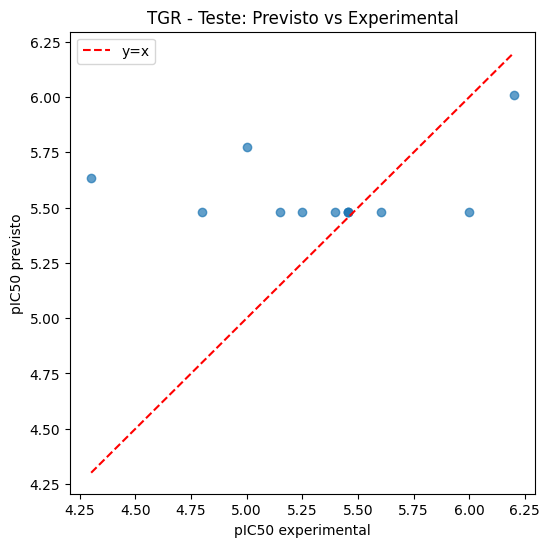

Real: 5.25 | Previsto: 5.48 | Erro: 0.23
Real: 6.00 | Previsto: 5.48 | Erro: 0.52
Real: 5.40 | Previsto: 5.48 | Erro: 0.08
Real: 5.00 | Previsto: 5.77 | Erro: 0.77
Real: 5.46 | Previsto: 5.48 | Erro: 0.03
Real: 5.15 | Previsto: 5.48 | Erro: 0.33
Real: 4.30 | Previsto: 5.64 | Erro: 1.33
Real: 5.60 | Previsto: 5.48 | Erro: 0.12
Real: 5.46 | Previsto: 5.48 | Erro: 0.03
Real: 4.80 | Previsto: 5.48 | Erro: 0.68
Real: 5.46 | Previsto: 5.48 | Erro: 0.03
Real: 6.20 | Previsto: 6.01 | Erro: 0.19


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_tgr_test, tgr_pred_test, alpha=0.7)
plt.plot([y_tgr_test.min(), y_tgr_test.max()], [y_tgr_test.min(), y_tgr_test.max()], 'r--', label='y=x')
plt.xlabel('pIC50 experimental')
plt.ylabel('pIC50 previsto')
plt.title('TGR - Teste: Previsto vs Experimental')
plt.legend()
plt.show()

for real, pred in zip(y_tgr_test, tgr_pred_test):
    print(f"Real: {real:.2f} | Previsto: {pred:.2f} | Erro: {abs(real-pred):.2f}")

calcular MAE também, pra ter o quadro completo

In [ ]:
from sklearn.metrics import mean_absolute_error

tgr_mae_test = mean_absolute_error(y_tgr_test, tgr_pred_test)
print(f"TGR - MAE teste: {tgr_mae_test:.3f}")

# Sem o outlier (pIC50=4.30) para referência
mask = y_tgr_test != 4.30
tgr_rmse_sem_outlier = np.sqrt(np.mean((y_tgr_test[mask] - tgr_pred_test[mask])**2))
print(f"TGR - RMSE teste sem o outlier: {tgr_rmse_sem_outlier:.3f}")

TGR - MAE teste: 0.362
TGR - RMSE teste sem o outlier: 0.527


Agora vamos para a Fase 5.6 — análise de consenso entre RF e HistGB, exigida pela sua proposta oficial (só se aplica ao smHDAC8, já que o TGR tem só um modelo final):

In [ ]:
import pandas as pd

def consensus_analysis(rf_model, hgb_model, X, compound_ids):
    pred_rf = rf_model.predict(X)
    pred_hgb = hgb_model.predict(X)

    df_consensus = pd.DataFrame({
        'molecule_chembl_id': compound_ids,
        'pIC50_RF': pred_rf,
        'pIC50_HGB': pred_hgb,
    })
    df_consensus['pIC50_mean'] = df_consensus[['pIC50_RF', 'pIC50_HGB']].mean(axis=1)
    df_consensus['pIC50_std'] = df_consensus[['pIC50_RF', 'pIC50_HGB']].std(axis=1)
    df_consensus['CV%'] = (df_consensus['pIC50_std'] / df_consensus['pIC50_mean']) * 100

    return df_consensus

hdac8_consensus_test = consensus_analysis(
    hdac8_rf_final, hdac8_hgb_final, X_hdac8_test, hdac8_test['molecule_chembl_id'].values
)

print(hdac8_consensus_test.describe())
print()
print(hdac8_consensus_test.head(10))

        pIC50_RF  pIC50_HGB  pIC50_mean  pIC50_std        CV%
count  43.000000  43.000000   43.000000  43.000000  43.000000
mean    4.847575   4.883935    4.865755   0.059173   1.239704
std     0.719621   0.721371    0.717375   0.077893   1.638594
min     4.522879   4.452444    4.487661   0.001366   0.030186
25%     4.522879   4.505283    4.514789   0.024961   0.460291
50%     4.522982   4.564399    4.546681   0.036455   0.740350
75%     4.557852   4.733849    4.646342   0.049210   1.095581
max     6.729213   6.783570    6.756392   0.394996   8.143593

  molecule_chembl_id  pIC50_RF  pIC50_HGB  pIC50_mean  pIC50_std       CV%
0      CHEMBL4100364  4.659673   4.564399    4.612036   0.067368  1.460706
1      CHEMBL4083112  4.524009   4.901016    4.712513   0.266585  5.656952
2      CHEMBL3771362  4.659673   4.564399    4.612036   0.067368  1.460706
3      CHEMBL4093433  4.522879   4.556344    4.539611   0.023663  0.521263
4      CHEMBL4100153  4.524358   4.526290    4.525324   0.001366  

Vamos salvar tudo isso antes de seguir, para não perder nada se o kernel reiniciar:

In [ ]:
import joblib
import os

os.makedirs('models', exist_ok=True)

joblib.dump(tgr_pls_final, 'models/tgr_pls_final.pkl')
joblib.dump(hdac8_rf_final, 'models/hdac8_rf_final.pkl')
joblib.dump(hdac8_hgb_final, 'models/hdac8_hgb_final.pkl')

# Salva também a lista de features usadas por cada modelo (essencial para reaplicar depois)
import json
with open('models/tgr_features.json', 'w') as f:
    json.dump(tgr_features_reduced, f)
with open('models/hdac8_features.json', 'w') as f:
    json.dump(hdac8_features, f)

hdac8_consensus_test.to_csv('data/smHDAC8/smHDAC8_consensus_test.csv', index=False)

print("Modelos e features salvos em models/")

Modelos e features salvos em models/


Caracterizar seus 57 (TGR) e 214 (smHDAC8) compostos de treino no TCC — mostrar quantos já são drug-like

In [ ]:
def lipinski_evaluation(df, mw_col='MW', logp_col='LogP', hbd_col='HBD', hba_col='HBA'):
    df = df.copy()

    df['violacao_MW'] = df[mw_col] > 500
    df['violacao_LogP'] = df[logp_col] > 5
    df['violacao_HBD'] = df[hbd_col] > 5
    df['violacao_HBA'] = df[hba_col] > 10

    df['num_violacoes'] = df[['violacao_MW', 'violacao_LogP', 'violacao_HBD', 'violacao_HBA']].sum(axis=1)
    df['drug_like'] = df['num_violacoes'] <= 1  # padrão: até 1 violação ainda é aceitável

    return df

tgr_qsar = lipinski_evaluation(tgr_qsar)
hdac8_qsar = lipinski_evaluation(hdac8_qsar)

print("=== TGR ===")
print(f"Compostos drug-like (≤1 violação): {tgr_qsar['drug_like'].sum()} de {len(tgr_qsar)}")
print(tgr_qsar['num_violacoes'].value_counts().sort_index())

print("\n=== smHDAC8 ===")
print(f"Compostos drug-like (≤1 violação): {hdac8_qsar['drug_like'].sum()} de {len(hdac8_qsar)}")
print(hdac8_qsar['num_violacoes'].value_counts().sort_index())

=== TGR ===
Compostos drug-like (≤1 violação): 57 de 57
num_violacoes
0    53
1     4
Name: count, dtype: int64

=== smHDAC8 ===
Compostos drug-like (≤1 violação): 192 de 214
num_violacoes
0    174
1     18
2     22
Name: count, dtype: int64


In [ ]:
# Salvar atualizado
tgr_qsar.to_csv('data/TGR/TGR_qsar_dataset.csv', index=False)
hdac8_qsar.to_csv('data/smHDAC8/smHDAC8_qsar_dataset.csv', index=False)
print("Salvo com avaliação de Lipinski incluída!")

Salvo com avaliação de Lipinski incluída!


# Fase 6 — triagem virtual no ZINC Database

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving ZINC-downloader-2D-smi (1).uri to ZINC-downloader-2D-smi (1).uri


In [ ]:
# Ver o conteúdo do arquivo .uri (é só texto, uma URL por linha)
with open('ZINC-downloader-2D-smi (1).uri') as f:
    urls = f.read().splitlines()

print(f"Total de links: {len(urls)}")
print("Primeiras 3 URLs:")
for u in urls[:3]:
    print(u)

Total de links: 160
Primeiras 3 URLs:
http://files.docking.org/2D/BA/BAAA.smi
http://files.docking.org/2D/BA/BAAB.smi
http://files.docking.org/2D/BA/BABA.smi


In [ ]:
import os

os.makedirs('zinc_raw', exist_ok=True)

for i, url in enumerate(urls):
    os.system(f'wget -q -P zinc_raw/ "{url}"')
    if (i+1) % 20 == 0:
        print(f"{i+1}/{len(urls)} baixados...")

print("Download concluído!")

20/160 baixados...
40/160 baixados...
60/160 baixados...
80/160 baixados...
100/160 baixados...
120/160 baixados...
140/160 baixados...
160/160 baixados...
Download concluído!


In [ ]:
!cat zinc_raw/*.smi > zinc_todos.smi
!wc -l zinc_todos.smi

1142690 zinc_todos.smi


In [ ]:
# Ver as primeiras linhas para confirmar o formato interno de cada arquivo
!head -5 zinc_todos.smi

smiles zinc_id
COCCn1cc(C[C@H]2NC(=O)NC2=O)nn1 98210274
Cn1cc(S(N)(=O)=O)cc1C(=O)C(=O)O 238833219
O=C(O)[C@@H]1CS(=O)(=O)CC12CNC2 1775958591
CC1(C)O[C@@H]2O[C@@H]([C@H](O)CO)[C@@H](O)[C@@H]2O1 519804


# Amostragem aleatória

In [ ]:
# Remove a linha de cabeçalho antes de amostrar, e faz a amostragem aleatória
!tail -n +2 zinc_todos.smi | shuf -n 15000 > zinc_amostra_15k.smi
!wc -l zinc_amostra_15k.smi

15000 zinc_amostra_15k.smi


In [ ]:
import pandas as pd

df_zinc = pd.read_csv('zinc_amostra_15k.smi', sep=' ', header=None, names=['smiles', 'zinc_id'])
print(f"Amostra carregada: {len(df_zinc)} compostos")
df_zinc.head()

Amostra carregada: 15000 compostos


,smiles,zinc_id
0,O=C(Nc1ccc2ccccc2c1)C(=O)[C@@H]1C(=O)Nc2ccccc21,101741343
1,NC1(Cc2cccc(C(F)(F)F)c2)CC1,84056017
2,C#Cc1cccc(N(Cc2ccncc2)C(=O)c2cncc(F)c2)c1,193550090
3,c1ccc([C@H](N2CCOCC2)n2nc3ccccc3n2)cc1,34255548
4,COc1cccc(OC)c1CN1CCC2(CC1)c1ccccc1[C@@H](OC)[C...,72168698


Amostra carregada com sucesso, 15.000 compostos prontos. Agora vamos aplicar o mesmo pipeline de padronização e descritores usado no TGR/smHDAC8.

Passo 1 — Padronização (RDKit)

In [ ]:
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

def standardize_mol(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    try:
        frag_chooser = rdMolStandardize.LargestFragmentChooser()
        mol = frag_chooser.choose(mol)

        tautomer_enumerator = rdMolStandardize.TautomerEnumerator()
        mol = tautomer_enumerator.Canonicalize(mol)

        uncharger = rdMolStandardize.Uncharger()
        mol = uncharger.uncharge(mol)

        return Chem.MolToSmiles(mol)
    except Exception:
        return None

print("Padronizando amostra do ZINC...")
df_zinc['smiles_std'] = df_zinc['smiles'].apply(standardize_mol)

n_falhas = df_zinc['smiles_std'].isna().sum()
df_zinc = df_zinc.dropna(subset=['smiles_std']).reset_index(drop=True)

print(f"Falhas na padronização: {n_falhas}")
print(f"Compostos válidos após padronização: {len(df_zinc)}")

Padronizando amostra do ZINC...


A saída de streaming foi truncada nas últimas 5000 linhas.
[03:44:35] Running Uncharger
[03:44:35] Running LargestFragmentChooser
[03:44:35] Running Uncharger
[03:44:35] Running LargestFragmentChooser
[03:44:35] Can't kekulize mol.  Unkekulized atoms: 2 5 18
[03:44:35] Can't kekulize mol.  Unkekulized atoms: 1 2 5
[03:44:35] Can't kekulize mol.  Unkekulized atoms: 2 5 18
[03:44:35] Can't kekulize mol.  Unkekulized atoms: 1 2 5
[03:44:35] Running Uncharger
[03:44:35] Running LargestFragmentChooser
[03:44:35] Running Uncharger
[03:44:35] Running LargestFragmentChooser
[03:44:35] Running Uncharger
[03:44:35] Running LargestFragmentChooser
[03:44:35] Running Uncharger
[03:44:35] Running LargestFragmentChooser
[03:44:35] Running Uncharger
[03:44:35] Running LargestFragmentChooser
[03:44:35] Running Uncharger
[03:44:35] Running LargestFragmentChooser
[03:44:35] Running Uncharger
[03:44:35] Running LargestFragmentChooser
[03:44:35] Running Uncharger
[03:44:35] Running LargestFragmentChooser
[

Falhas na padronização: 3
Compostos válidos após padronização: 14997


# Passo 2 — Cálculo dos descritores (Lipinski + ECFP4 + MACCS)

In [ ]:
from rdkit.Chem import Descriptors, Lipinski, MACCSkeys
from rdkit.Chem import rdFingerprintGenerator
import pandas as pd

def calc_lipinski(df, smiles_col='smiles_std'):
    rows = []
    for smi in df[smiles_col]:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            rows.append([None]*5)
            continue
        rows.append([
            Descriptors.MolWt(mol),
            Descriptors.MolLogP(mol),
            Lipinski.NumHDonors(mol),
            Lipinski.NumHAcceptors(mol),
            Descriptors.TPSA(mol)
        ])
    return pd.DataFrame(rows, columns=['MW', 'LogP', 'HBD', 'HBA', 'TPSA'])


def calc_ecfp4(df, smiles_col='smiles_std', n_bits=2048):
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=n_bits)
    fps = []
    for smi in df[smiles_col]:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            fps.append([0]*n_bits)
            continue
        fp = generator.GetFingerprintAsNumPy(mol)
        fps.append(list(fp))
    cols = [f'ECFP4_{i}' for i in range(n_bits)]
    return pd.DataFrame(fps, columns=cols)


def calc_maccs(df, smiles_col='smiles_std'):
    fps = []
    for smi in df[smiles_col]:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            fps.append([0]*167)
            continue
        fp = MACCSkeys.GenMACCSKeys(mol)
        fps.append(list(fp))
    cols = [f'MACCS_{i}' for i in range(167)]
    return pd.DataFrame(fps, columns=cols)


print("Calculando descritores da amostra do ZINC (pode levar alguns minutos)...")
lipinski_zinc = calc_lipinski(df_zinc)
ecfp4_zinc = calc_ecfp4(df_zinc)
maccs_zinc = calc_maccs(df_zinc)

zinc_qsar = pd.concat([
    df_zinc[['zinc_id', 'smiles_std']].reset_index(drop=True),
    lipinski_zinc, ecfp4_zinc, maccs_zinc
], axis=1)

zinc_qsar = zinc_qsar.dropna(subset=['MW']).reset_index(drop=True)
print(f"Descritores calculados para {len(zinc_qsar)} compostos, {zinc_qsar.shape[1]} colunas")

Calculando descritores da amostra do ZINC (pode levar alguns minutos)...
Descritores calculados para 14997 compostos, 2222 colunas


# Passo 3 — Salvar checkpoint

In [ ]:
import os
os.makedirs('data/ZINC', exist_ok=True)
zinc_qsar.to_csv('data/ZINC/zinc_qsar_dataset.csv', index=False)
print("Checkpoint salvo!")

Checkpoint salvo!


# Agora vamos aplicar os modelos treinados (TGR e smHDAC8)

Como os modelos foram treinados com um conjunto reduzido e específico de features (após pré-tratamento de variância/correlação), é essencial usar exatamente as mesmas colunas, na mesma ordem, para o ZINC.

In [ ]:
import joblib
import json

tgr_pls_final = joblib.load('models/tgr_pls_final.pkl')
hdac8_rf_final = joblib.load('models/hdac8_rf_final.pkl')
hdac8_hgb_final = joblib.load('models/hdac8_hgb_final.pkl')

with open('models/tgr_features.json') as f:
    tgr_features_reduced = json.load(f)
with open('models/hdac8_features.json') as f:
    hdac8_features = json.load(f)

print(f"TGR espera {len(tgr_features_reduced)} features")
print(f"smHDAC8 espera {len(hdac8_features)} features")

TGR espera 30 features
smHDAC8 espera 398 features


In [ ]:
missing_tgr = [f for f in tgr_features_reduced if f not in zinc_qsar.columns]
missing_hdac8 = [f for f in hdac8_features if f not in zinc_qsar.columns]

print(f"Features faltando para TGR: {len(missing_tgr)}")
print(f"Features faltando para smHDAC8: {len(missing_hdac8)}")

Features faltando para TGR: 0
Features faltando para smHDAC8: 0


# Aplicar os modelos TGR e smHDAC8 no ZINC

In [ ]:
import numpy as np

X_zinc_tgr = zinc_qsar[tgr_features_reduced].values
X_zinc_hdac8 = zinc_qsar[hdac8_features].values

# TGR - PLS
pred_tgr = tgr_pls_final.predict(X_zinc_tgr).ravel()

# smHDAC8 - RF e HistGB
pred_hdac8_rf = hdac8_rf_final.predict(X_zinc_hdac8)
pred_hdac8_hgb = hdac8_hgb_final.predict(X_zinc_hdac8)

zinc_results = zinc_qsar[['zinc_id', 'smiles_std', 'MW', 'LogP', 'HBD', 'HBA', 'TPSA']].copy()

zinc_results['pIC50_TGR'] = pred_tgr
zinc_results['pIC50_HDAC8_RF'] = pred_hdac8_rf
zinc_results['pIC50_HDAC8_HGB'] = pred_hdac8_hgb
zinc_results['pIC50_HDAC8_mean'] = zinc_results[['pIC50_HDAC8_RF', 'pIC50_HDAC8_HGB']].mean(axis=1)
zinc_results['pIC50_HDAC8_std'] = zinc_results[['pIC50_HDAC8_RF', 'pIC50_HDAC8_HGB']].std(axis=1)
zinc_results['HDAC8_CV%'] = (zinc_results['pIC50_HDAC8_std'] / zinc_results['pIC50_HDAC8_mean']) * 100

print(f"Previsões geradas para {len(zinc_results)} compostos")
zinc_results.head()

Previsões geradas para 14997 compostos


,zinc_id,smiles_std,MW,LogP,HBD,HBA,TPSA,pIC50_TGR,pIC50_HDAC8_RF,pIC50_HDAC8_HGB,pIC50_HDAC8_mean,pIC50_HDAC8_std,HDAC8_CV%
0,101741343,O=C(Nc1ccc2ccccc2c1)C(=O)c1c(O)[nH]c2ccccc12,330.343,3.8481,3,3,82.19,5.747132,5.914207,5.808562,5.861384,0.074702,1.274484
1,84056017,NC1(Cc2cccc(C(F)(F)F)c2)CC1,215.218,2.7392,1,1,26.02,6.325309,5.350878,5.176918,5.263898,0.123008,2.336832
2,193550090,C#Cc1cccc(N(Cc2ccncc2)C(=O)c2cncc(F)c2)c1,331.350,3.4440,0,3,46.09,6.281523,5.193900,5.202613,5.198256,0.006161,0.118524
3,34255548,c1ccc([C@H](N2CCOCC2)n2nc3ccccc3n2)cc1,294.358,2.3104,0,4,43.18,5.787313,5.072112,4.605736,4.838924,0.329778,6.815108
4,72168698,COc1cccc(OC)c1CN1CCC2(CC1)c1ccccc1[C@@H](OC)[C...,383.488,3.2996,1,5,51.16,6.012639,5.823352,5.323825,5.573588,0.353218,6.337359


# Aplicar filtro de Lipinski (já que calculamos os descritores)

In [ ]:
zinc_results['violacao_MW'] = zinc_results['MW'] > 500
zinc_results['violacao_LogP'] = zinc_results['LogP'] > 5
zinc_results['violacao_HBD'] = zinc_results['HBD'] > 5
zinc_results['violacao_HBA'] = zinc_results['HBA'] > 10
zinc_results['num_violacoes'] = zinc_results[['violacao_MW', 'violacao_LogP', 'violacao_HBD', 'violacao_HBA']].sum(axis=1)
zinc_results['drug_like'] = zinc_results['num_violacoes'] <= 1

print(f"Compostos drug-like: {zinc_results['drug_like'].sum()} de {len(zinc_results)}")

Compostos drug-like: 14959 de 14997


In [ ]:
Ranking final — top candidatos para cada alvo

In [ ]:
# Top 20 para smHDAC8: alta atividade prevista + alto consenso (CV% baixo) + drug-like
top_hdac8 = zinc_results[zinc_results['drug_like']].sort_values(
    ['pIC50_HDAC8_mean', 'HDAC8_CV%'], ascending=[False, True]
).head(20)

print("=== TOP 20 candidatos - smHDAC8 ===")
print(top_hdac8[['zinc_id', 'pIC50_HDAC8_mean', 'HDAC8_CV%', 'MW', 'LogP']])

# Top 20 para TGR: alta atividade prevista + drug-like
top_tgr = zinc_results[zinc_results['drug_like']].sort_values(
    'pIC50_TGR', ascending=False
).head(20)

print("\n=== TOP 20 candidatos - TGR ===")
print(top_tgr[['zinc_id', 'pIC50_TGR', 'MW', 'LogP']])

=== TOP 20 candidatos - smHDAC8 ===
          zinc_id  pIC50_HDAC8_mean  HDAC8_CV%       MW     LogP
9225      6704620          6.289627   3.592123  349.770  3.39610
12966      453444          6.252397   2.808416  329.381  3.33844
1523     23057091          6.249734   3.382340  443.912  4.49100
11313    95474601          6.238318   3.082535  337.379  3.39760
8486     15200697          6.211644   2.469979  342.323  3.20800
9242    194172361          6.198370   2.813466  328.393  3.30554
4711     89404370          6.190639   1.956384  339.326  3.05030
1066     10370354          6.183957   3.420939  332.425  3.23566
2147      4731564          6.182987   0.998763  349.368  3.09714
4559     25312968          6.182736   3.434820  288.278  2.18550
9265      4686327          6.182109   0.574641  378.768  3.20260
1560     40131197          6.177111   1.841462  339.376  3.24400
2820     29113373          6.158679   0.047684  398.469  3.30558
13344    32804210          6.145144   1.392263  383.33

In [ ]:
zinc_results.to_csv('data/ZINC/zinc_screening_results.csv', index=False)
top_hdac8.to_csv('data/ZINC/top20_hdac8.csv', index=False)
top_tgr.to_csv('data/ZINC/top20_tgr.csv', index=False)
print("Resultados da triagem salvos!")

Resultados da triagem salvos!


# Analogos do Praziquantel

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving substances.smi to substances.smi


In [ ]:
import pandas as pd

# Primeiro, vamos ver o formato exato antes de carregar oficialmente
with open('substances.smi') as f:
    for i, line in enumerate(f):
        print(repr(line))
        if i >= 4:
            break

'O=C(C1CCCCC1)N1CC(=O)N2CCc3ccccc3[C@@H]2C1 ZINC000000000655\n'
'O=C(C1CCCCC1)N1CC(=O)N2CCc3ccccc3[C@H]2C1 ZINC000000403566\n'
'O=C(C1CCCC1)N1CC(=O)N2CCc3ccccc3[C@@H]2C1 ZINC000039434573\n'
'O=C(C1CCCC1)N1CC(=O)N2CCc3ccccc3[C@H]2C1 ZINC000039434572\n'
'O=C(C1CCCCC1)N1CC(=O)N2CCCc3ccccc3[C@@H]2C1 ZINC000000000253\n'


In [ ]:
df_pzq_analogs = pd.read_csv('substances.smi', sep=' ', header=0, names=['smiles', 'zinc_id'])

print(f"Total de análogos do PZQ: {len(df_pzq_analogs)}")
df_pzq_analogs.head()

Total de análogos do PZQ: 84


,smiles,zinc_id
0,O=C(C1CCCCC1)N1CC(=O)N2CCc3ccccc3[C@H]2C1,ZINC000000403566
1,O=C(C1CCCC1)N1CC(=O)N2CCc3ccccc3[C@@H]2C1,ZINC000039434573
2,O=C(C1CCCC1)N1CC(=O)N2CCc3ccccc3[C@H]2C1,ZINC000039434572
3,O=C(C1CCCCC1)N1CC(=O)N2CCCc3ccccc3[C@@H]2C1,ZINC000000000253
4,O=C(C1CCCCC1)N1CC(=O)N2CCCc3ccccc3[C@H]2C1,ZINC000001842759


In [ ]:
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

def standardize_mol(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    try:
        frag_chooser = rdMolStandardize.LargestFragmentChooser()
        mol = frag_chooser.choose(mol)
        tautomer_enumerator = rdMolStandardize.TautomerEnumerator()
        mol = tautomer_enumerator.Canonicalize(mol)
        uncharger = rdMolStandardize.Uncharger()
        mol = uncharger.uncharge(mol)
        return Chem.MolToSmiles(mol)
    except Exception:
        return None

df_pzq_analogs['smiles_std'] = df_pzq_analogs['smiles'].apply(standardize_mol)
n_falhas = df_pzq_analogs['smiles_std'].isna().sum()
df_pzq_analogs = df_pzq_analogs.dropna(subset=['smiles_std']).reset_index(drop=True)

print(f"Falhas na padronização: {n_falhas}")
print(f"Compostos válidos: {len(df_pzq_analogs)}")

[04:57:24] Running LargestFragmentChooser
[04:57:24] Running Uncharger
[04:57:24] Running LargestFragmentChooser
[04:57:24] Running Uncharger
[04:57:24] Running LargestFragmentChooser
[04:57:25] Running Uncharger
[04:57:25] Running LargestFragmentChooser
[04:57:25] Running Uncharger
[04:57:25] Running LargestFragmentChooser
[04:57:25] Running Uncharger
[04:57:25] Running LargestFragmentChooser
[04:57:25] Running Uncharger
[04:57:25] Running LargestFragmentChooser
[04:57:25] Running Uncharger
[04:57:25] Running LargestFragmentChooser
[04:57:25] Running Uncharger
[04:57:25] Running LargestFragmentChooser
[04:57:25] Running Uncharger
[04:57:25] Running LargestFragmentChooser
[04:57:25] Running Uncharger
[04:57:25] Running LargestFragmentChooser
[04:57:25] Running Uncharger
[04:57:25] Running LargestFragmentChooser
[04:57:25] Running Uncharger
[04:57:25] Running LargestFragmentChooser
[04:57:25] Running Uncharger
[04:57:25] Running LargestFragmentChooser
[04:57:25] Running Uncharger
[04:57

Falhas na padronização: 0
Compostos válidos: 84


[04:57:26] Running LargestFragmentChooser
[04:57:26] Running Uncharger
[04:57:26] Running LargestFragmentChooser
[04:57:26] Running Uncharger
[04:57:26] Running LargestFragmentChooser
[04:57:26] Running Uncharger
[04:57:26] Running LargestFragmentChooser
[04:57:26] Running Uncharger
[04:57:26] Running LargestFragmentChooser
[04:57:26] Running Uncharger


In [ ]:
from rdkit.Chem import Descriptors, Lipinski, MACCSkeys
from rdkit.Chem import rdFingerprintGenerator

def calc_lipinski(df, smiles_col='smiles_std'):
    rows = []
    for smi in df[smiles_col]:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            rows.append([None]*5)
            continue
        rows.append([
            Descriptors.MolWt(mol), Descriptors.MolLogP(mol),
            Lipinski.NumHDonors(mol), Lipinski.NumHAcceptors(mol), Descriptors.TPSA(mol)
        ])
    return pd.DataFrame(rows, columns=['MW', 'LogP', 'HBD', 'HBA', 'TPSA'])

def calc_ecfp4(df, smiles_col='smiles_std', n_bits=2048):
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=n_bits)
    fps = []
    for smi in df[smiles_col]:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            fps.append([0]*n_bits)
            continue
        fps.append(list(generator.GetFingerprintAsNumPy(mol)))
    return pd.DataFrame(fps, columns=[f'ECFP4_{i}' for i in range(n_bits)])

def calc_maccs(df, smiles_col='smiles_std'):
    fps = []
    for smi in df[smiles_col]:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            fps.append([0]*167)
            continue
        fps.append(list(MACCSkeys.GenMACCSKeys(mol)))
    return pd.DataFrame(fps, columns=[f'MACCS_{i}' for i in range(167)])

lipinski_pzq = calc_lipinski(df_pzq_analogs)
ecfp4_pzq = calc_ecfp4(df_pzq_analogs)
maccs_pzq = calc_maccs(df_pzq_analogs)

pzq_analogs_qsar = pd.concat([
    df_pzq_analogs[['zinc_id', 'smiles_std']].reset_index(drop=True),
    lipinski_pzq, ecfp4_pzq, maccs_pzq
], axis=1)

print(f"Descritores calculados para {len(pzq_analogs_qsar)} compostos")

Descritores calculados para 84 compostos


# Aplicar os modelos nos análogos do PZQ

In [ ]:
X_pzq_tgr = pzq_analogs_qsar[tgr_features_reduced].values
X_pzq_hdac8 = pzq_analogs_qsar[hdac8_features].values

pred_pzq_tgr = tgr_pls_final.predict(X_pzq_tgr).ravel()
pred_pzq_hdac8_rf = hdac8_rf_final.predict(X_pzq_hdac8)
pred_pzq_hdac8_hgb = hdac8_hgb_final.predict(X_pzq_hdac8)

pzq_results = pzq_analogs_qsar[['zinc_id', 'smiles_std', 'MW', 'LogP', 'HBD', 'HBA', 'TPSA']].copy()
pzq_results['pIC50_TGR'] = pred_pzq_tgr
pzq_results['pIC50_HDAC8_RF'] = pred_pzq_hdac8_rf
pzq_results['pIC50_HDAC8_HGB'] = pred_pzq_hdac8_hgb
pzq_results['pIC50_HDAC8_mean'] = pzq_results[['pIC50_HDAC8_RF', 'pIC50_HDAC8_HGB']].mean(axis=1)
pzq_results['pIC50_HDAC8_std'] = pzq_results[['pIC50_HDAC8_RF', 'pIC50_HDAC8_HGB']].std(axis=1)
pzq_results['HDAC8_CV%'] = (pzq_results['pIC50_HDAC8_std'] / pzq_results['pIC50_HDAC8_mean']) * 100

# Lipinski
pzq_results['num_violacoes'] = (
    (pzq_results['MW'] > 500).astype(int) +
    (pzq_results['LogP'] > 5).astype(int) +
    (pzq_results['HBD'] > 5).astype(int) +
    (pzq_results['HBA'] > 10).astype(int)
)
pzq_results['drug_like'] = pzq_results['num_violacoes'] <= 1

pzq_results = pzq_results.sort_values('pIC50_HDAC8_mean', ascending=False)
print(f"Compostos drug-like: {pzq_results['drug_like'].sum()} de {len(pzq_results)}")
pzq_results.to_csv('data/ZINC/pzq_analogs_results.csv', index=False)
pzq_results.head(10)

Compostos drug-like: 84 de 84


,zinc_id,smiles_std,MW,LogP,HBD,HBA,TPSA,pIC50_TGR,pIC50_HDAC8_RF,pIC50_HDAC8_HGB,pIC50_HDAC8_mean,pIC50_HDAC8_std,HDAC8_CV%,num_violacoes,drug_like
70,ZINC001184223326,C[C@@H]1c2ccccc2CCN1C(=O)CCCC1CCCCC1,299.458,4.8829,0,1,20.31,6.012639,5.592052,5.483140,5.537596,0.077012,1.390716,0,True
71,ZINC001184223324,C[C@H]1c2ccccc2CCN1C(=O)CCCC1CCCCC1,299.458,4.8829,0,1,20.31,6.012639,5.592052,5.483140,5.537596,0.077012,1.390716,0,True
76,ZINC000548715252,C[C@H]1c2ccccc2CCN1C(=O)CCN(C)C1CCCCC1,314.473,3.7869,0,2,23.55,5.858953,5.414586,5.123404,5.268995,0.205897,3.907708,0,True
75,ZINC000548715253,C[C@@H]1c2ccccc2CCN1C(=O)CCN(C)C1CCCCC1,314.473,3.7869,0,2,23.55,5.858953,5.414586,5.123404,5.268995,0.205897,3.907708,0,True
82,ZINC000036125842,O=C(N1CCOCC1)N1CCN2CCc3ccccc3[C@@H]2C1,301.390,1.3536,0,3,36.02,6.012639,5.077354,4.399862,4.738608,0.479059,10.109693,0,True
83,ZINC000036125841,O=C(N1CCOCC1)N1CCN2CCc3ccccc3[C@H]2C1,301.390,1.3536,0,3,36.02,6.012639,5.077354,4.399862,4.738608,0.479059,10.109693,0,True
55,ZINC000033753367,O=C(C1CCCCC1)N1C[C@@H]2c3ccccc3CCN2S(=O)(=O)C1,348.468,2.2956,0,3,57.69,5.932818,5.071683,4.400710,4.736196,0.474449,10.017513,0,True
56,ZINC000033753368,O=C(C1CCCCC1)N1C[C@H]2c3ccccc3CCN2S(=O)(=O)C1,348.468,2.2956,0,3,57.69,5.932818,5.071683,4.400710,4.736196,0.474449,10.017513,0,True
80,ZINC000062691024,C[C@@H]1CN(C(=O)C2CCCCC2)CCN1CCc1ccccc1,314.473,3.3421,0,2,23.55,5.932818,4.930141,4.535262,4.732702,0.279222,5.899835,0,True
81,ZINC000062691025,C[C@H]1CN(C(=O)C2CCCCC2)CCN1CCc1ccccc1,314.473,3.3421,0,2,23.55,5.932818,4.930141,4.535262,4.732702,0.279222,5.899835,0,True


# Comparação direta entre as duas camadas

In [ ]:
print("=== Comparação Camada 1 (Tranche/In-Stock) vs Camada 2 (Análogos PZQ) ===\n")

print("--- smHDAC8 ---")
print(f"Camada 1 (n={len(zinc_results)}): pIC50 médio = {zinc_results['pIC50_HDAC8_mean'].mean():.3f}, máximo = {zinc_results['pIC50_HDAC8_mean'].max():.3f}")
print(f"Camada 2 (n={len(pzq_results)}): pIC50 médio = {pzq_results['pIC50_HDAC8_mean'].mean():.3f}, máximo = {pzq_results['pIC50_HDAC8_mean'].max():.3f}")

print("\n--- TGR ---")
print(f"Camada 1 (n={len(zinc_results)}): pIC50 médio = {zinc_results['pIC50_TGR'].mean():.3f}, máximo = {zinc_results['pIC50_TGR'].max():.3f}")
print(f"Camada 2 (n={len(pzq_results)}): pIC50 médio = {pzq_results['pIC50_TGR'].mean():.3f}, máximo = {pzq_results['pIC50_TGR'].max():.3f}")

=== Comparação Camada 1 (Tranche/In-Stock) vs Camada 2 (Análogos PZQ) ===

--- smHDAC8 ---
Camada 1 (n=14997): pIC50 médio = 5.164, máximo = 6.290
Camada 2 (n=84): pIC50 médio = 4.593, máximo = 5.538

--- TGR ---
Camada 1 (n=14997): pIC50 médio = 5.977, máximo = 8.139
Camada 2 (n=84): pIC50 médio = 5.966, máximo = 6.147


# Fechando a Fase 6

Você já tem os elementos centrais: ranking por camada, comparação estatística, e candidatos priorizados. Vale consolidar os top 10-20 finais (das duas camadas juntas) num único arquivo de saída:

In [ ]:
zinc_results['origem'] = 'Tranche_InStock'
pzq_results['origem'] = 'Analogo_PZQ'

colunas_comuns = ['zinc_id', 'smiles_std', 'MW', 'LogP', 'pIC50_TGR', 'pIC50_HDAC8_mean', 'HDAC8_CV%', 'drug_like', 'origem']

candidatos_finais = pd.concat([
    zinc_results[zinc_results['drug_like']][colunas_comuns],
    pzq_results[pzq_results['drug_like']][colunas_comuns]
]).sort_values('pIC50_HDAC8_mean', ascending=False).head(30)

candidatos_finais.to_csv('data/ZINC/candidatos_finais_top30.csv', index=False)
print(candidatos_finais.head(15))

         zinc_id                                         smiles_std       MW  \
9225     6704620          COC(=O)c1ccc(Cl)cc1NC(=O)c1ccc(OC)c(OC)c1  349.770   
12966     453444   Cc1ccc(C)c(NC(=S)NC(=O)c2cccc([N+](=O)[O-])c2)c1  329.381   
1523    23057091  COCC(=O)Nc1cccc(NC(=O)c2ccc(Cl)c(NC(=O)c3cccs3...  443.912   
11313   95474601          COc1ccc(NC(C)=O)cc1NC(=O)c1ccc2c(ccn2C)c1  337.379   
8486    15200697            COc1cc(C(=O)Nc2nc(C(C)=O)cs2)ccc1OC(F)F  342.323   
9242   194172361          Cc1ccc(NC(=O)c2ccc3c(c2)NC(=O)CS3)c(C)c1O  328.393   
4711    89404370       COC(=O)c1cc(C(=O)Nc2ccc(F)c(-n3cccc3)c2)ccn1  339.326   
1066    10370354       Cc1cc(C)cc(NC(=O)c2ccc(NS(C)(=O)=O)c(C)c2)c1  332.425   
2147     4731564  CCOC(=O)c1sc(NC(=O)c2ccc(C)c([N+](=O)[O-])c2)nc1C  349.368   
4559    25312968                COc1cc(F)ccc1NC(=O)c1cccc(C(N)=O)c1  288.278   
9265     4686327  COc1cccc(C(=O)N[C@H](CC(=O)O)c2cc([N+](=O)[O-]...  378.768   
1560    40131197          COC(=O)c1cccc(

adicionar um filtro PAINS antes de finalizar o ranking

In [ ]:
from rdkit.Chem import FilterCatalog
from rdkit.Chem.FilterCatalog import FilterCatalogParams

params = FilterCatalogParams()
params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
catalog = FilterCatalog.FilterCatalog(params)

def check_pains(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    entry = catalog.GetFirstMatch(mol)
    return entry.GetDescription() if entry else None

candidatos_finais['PAINS_alert'] = candidatos_finais['smiles_std'].apply(check_pains)

print(f"Candidatos com alerta PAINS: {candidatos_finais['PAINS_alert'].notna().sum()} de {len(candidatos_finais)}")
print(candidatos_finais[candidatos_finais['PAINS_alert'].notna()][['zinc_id', 'PAINS_alert']])

Candidatos com alerta PAINS: 0 de 30
Empty DataFrame
Columns: [zinc_id, PAINS_alert]
Index: []


In [ ]:
# Ranking final, priorizando quem passa em tudo: Lipinski + sem alerta PAINS
candidatos_limpos = candidatos_finais[candidatos_finais['PAINS_alert'].isna()].sort_values('pIC50_HDAC8_mean', ascending=False)

print(f"Candidatos finais aprovados (sem alerta PAINS): {len(candidatos_limpos)}")
candidatos_limpos.head(15)

Candidatos finais aprovados (sem alerta PAINS): 30


,zinc_id,smiles_std,MW,LogP,pIC50_TGR,pIC50_HDAC8_mean,HDAC8_CV%,drug_like,origem,PAINS_alert
9225,6704620,COC(=O)c1ccc(Cl)cc1NC(=O)c1ccc(OC)c(OC)c1,349.770,3.39610,6.348569,6.289627,3.592123,True,Tranche_InStock,None
12966,453444,Cc1ccc(C)c(NC(=S)NC(=O)c2cccc([N+](=O)[O-])c2)c1,329.381,3.33844,6.549721,6.252397,2.808416,True,Tranche_InStock,None
1523,23057091,COCC(=O)Nc1cccc(NC(=O)c2ccc(Cl)c(NC(=O)c3cccs3...,443.912,4.49100,6.255750,6.249734,3.382340,True,Tranche_InStock,None
11313,95474601,COc1ccc(NC(C)=O)cc1NC(=O)c1ccc2c(ccn2C)c1,337.379,3.39760,5.280776,6.238318,3.082535,True,Tranche_InStock,None
8486,15200697,COc1cc(C(=O)Nc2nc(C(C)=O)cs2)ccc1OC(F)F,342.323,3.20800,6.167792,6.211644,2.469979,True,Tranche_InStock,None
9242,194172361,Cc1ccc(NC(=O)c2ccc3c(c2)NC(=O)CS3)c(C)c1O,328.393,3.30554,6.418927,6.198370,2.813466,True,Tranche_InStock,None
4711,89404370,COC(=O)c1cc(C(=O)Nc2ccc(F)c(-n3cccc3)c2)ccn1,339.326,3.05030,5.280776,6.190639,1.956384,True,Tranche_InStock,None
1066,10370354,Cc1cc(C)cc(NC(=O)c2ccc(NS(C)(=O)=O)c(C)c2)c1,332.425,3.23566,6.348569,6.183957,3.420939,True,Tranche_InStock,None
2147,4731564,CCOC(=O)c1sc(NC(=O)c2ccc(C)c([N+](=O)[O-])c2)nc1C,349.368,3.09714,5.873724,6.182987,0.998763,True,Tranche_InStock,None
4559,25312968,COc1cc(F)ccc1NC(=O)c1cccc(C(N)=O)c1,288.278,2.18550,6.348569,6.182736,3.434820,True,Tranche_InStock,None


In [ ]:
candidatos_finais.to_csv('data/ZINC/candidatos_finais_top30_com_PAINS.csv', index=False)
candidatos_limpos.to_csv('data/ZINC/candidatos_finais_aprovados.csv', index=False)
print("Salvo!")

Salvo!


PARTE 1 — QSAR 3D (fechando a lacuna da proposta)

Vamos gerar conformação 3D real (embedding + otimização de geometria) e calcular descritores 3D verdadeiros (WHIM, GETAWAY, RDF, MORSE, autocorrelação 3D), complementando os fingerprints 2D que você já tem.

In [ ]:
print(tgr_qsar.columns.tolist()[:6])
print(hdac8_qsar.columns.tolist()[:6])

['molecule_chembl_id', 'canonical_smiles', 'pIC50', 'MW', 'LogP', 'HBD']
['molecule_chembl_id', 'canonical_smiles', 'pIC50', 'MW', 'LogP', 'HBD']


In [ ]:
# Identifica automaticamente qual coluna de SMILES existe
smiles_col_tgr = 'smiles_std' if 'smiles_std' in tgr_qsar.columns else 'canonical_smiles'
smiles_col_hdac8 = 'smiles_std' if 'smiles_std' in hdac8_qsar.columns else 'canonical_smiles'

print(f"Usando coluna '{smiles_col_tgr}' para TGR")
print(f"Usando coluna '{smiles_col_hdac8}' para smHDAC8")

Usando coluna 'canonical_smiles' para TGR
Usando coluna 'canonical_smiles' para smHDAC8


In [ ]:
print("Gerando descritores 3D para TGR...")
tgr_3d, tgr_3d_failed = generate_3d_and_descriptors(
    tgr_qsar[smiles_col_tgr].tolist(), tgr_qsar['molecule_chembl_id'].tolist()
)

print("Gerando descritores 3D para smHDAC8...")
hdac8_3d, hdac8_3d_failed = generate_3d_and_descriptors(
    hdac8_qsar[smiles_col_hdac8].tolist(), hdac8_qsar['molecule_chembl_id'].tolist()
)

Gerando descritores 3D para TGR...
Sucesso: 0 | Falhas: 57
Gerando descritores 3D para smHDAC8...
Sucesso: 0 | Falhas: 214


In [ ]:
smi_teste = tgr_qsar['smiles_std'].iloc[0] if 'smiles_std' in tgr_qsar.columns else tgr_qsar['canonical_smiles'].iloc[0]
print(f"SMILES de teste: {smi_teste}")

mol = Chem.MolFromSmiles(smi_teste)
print(f"Mol criado: {mol is not None}")

mol = Chem.AddHs(mol)
print(f"Hidrogênios adicionados: {mol.GetNumAtoms()} átomos")

embed_status = AllChem.EmbedMolecule(mol, randomSeed=42, useRandomCoords=True)
print(f"Status do embedding: {embed_status}")

if embed_status == 0:
    try:
        AllChem.MMFFOptimizeMolecule(mol, maxIters=500)
        print("Otimização MMFF: OK")
    except Exception as e:
        print(f"Erro na otimização MMFF: {e}")

    try:
        from rdkit.Chem import Descriptors3D
        pmi1 = Descriptors3D.PMI1(mol)
        print(f"PMI1 calculado: {pmi1}")
    except Exception as e:
        print(f"Erro no cálculo de descritores 3D: {e}")
else:
    print("Embedding falhou — esse é o problema raiz")


SMILES de teste: COc1ccc(C(=O)c2no[n+]([O-])c2C(=O)c2ccc(OC)cc2)cc1
Mol criado: True
Hidrogênios adicionados: 40 átomos
Status do embedding: 0
Otimização MMFF: OK
PMI1 calculado: 2212.9538785067843


In [ ]:
from rdkit.Chem import Descriptors3D

try:
    whim = Descriptors3D.WHIM(mol)
    print(f"WHIM calculado com sucesso: {len(whim)} valores")
    print(whim[:5])
except Exception as e:
    print(f"Erro no WHIM: {type(e).__name__}: {e}")

Erro no WHIM: AttributeError: module 'rdkit.Chem.Descriptors3D' has no attribute 'WHIM'


In [ ]:
try:
    whim = Descriptors3D.WHIM(mol, confId=-1)
    print(f"WHIM (com confId): {len(whim)} valores")
except Exception as e:
    print(f"Ainda com erro: {type(e).__name__}: {e}")

Ainda com erro: AttributeError: module 'rdkit.Chem.Descriptors3D' has no attribute 'WHIM'


In [ ]:
def generate_3d_and_descriptors_v2(smiles_list, ids_list):
    results = []
    failed = []
    for smi, cid in zip(smiles_list, ids_list):
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            failed.append(cid)
            continue
        mol = Chem.AddHs(mol)

        params = AllChem.ETKDGv3()
        params.randomSeed = 42
        embed_status = AllChem.EmbedMolecule(mol, params)
        if embed_status != 0:
            failed.append(cid)
            continue

        try:
            AllChem.MMFFOptimizeMolecule(mol, maxIters=500)
        except Exception:
            failed.append(cid)
            continue

        try:
            desc = {
                'id': cid,
                'PMI1': Descriptors3D.PMI1(mol),
                'PMI2': Descriptors3D.PMI2(mol),
                'PMI3': Descriptors3D.PMI3(mol),
                'NPR1': Descriptors3D.NPR1(mol),
                'NPR2': Descriptors3D.NPR2(mol),
                'RadiusOfGyration': Descriptors3D.RadiusOfGyration(mol),
                'InertialShapeFactor': Descriptors3D.InertialShapeFactor(mol),
                'Eccentricity': Descriptors3D.Eccentricity(mol),
                'Asphericity': Descriptors3D.Asphericity(mol),
                'SpherocityIndex': Descriptors3D.SpherocityIndex(mol),
            }
            results.append(desc)
        except Exception:
            failed.append(cid)
            continue

    print(f"Sucesso: {len(results)} | Falhas: {len(failed)}")
    return pd.DataFrame(results), failed

smiles_col_tgr = 'smiles_std' if 'smiles_std' in tgr_qsar.columns else 'canonical_smiles'
smiles_col_hdac8 = 'smiles_std' if 'smiles_std' in hdac8_qsar.columns else 'canonical_smiles'

print("Gerando descritores 3D (v2, sem WHIM) para TGR...")
tgr_3d, tgr_3d_failed = generate_3d_and_descriptors_v2(
    tgr_qsar[smiles_col_tgr].tolist(), tgr_qsar['molecule_chembl_id'].tolist()
)

print("Gerando descritores 3D (v2, sem WHIM) para smHDAC8...")
hdac8_3d, hdac8_3d_failed = generate_3d_and_descriptors_v2(
    hdac8_qsar[smiles_col_hdac8].tolist(), hdac8_qsar['molecule_chembl_id'].tolist()
)

Gerando descritores 3D (v2, sem WHIM) para TGR...
Sucesso: 57 | Falhas: 0
Gerando descritores 3D (v2, sem WHIM) para smHDAC8...
Sucesso: 214 | Falhas: 0


In [ ]:
tgr_qsar_3d = tgr_qsar.merge(tgr_3d, left_on='molecule_chembl_id', right_on='id', how='inner').drop(columns=['id'])
hdac8_qsar_3d = hdac8_qsar.merge(hdac8_3d, left_on='molecule_chembl_id', right_on='id', how='inner').drop(columns=['id'])

print(f"TGR com descritores 3D: {tgr_qsar_3d.shape}")
print(f"smHDAC8 com descritores 3D: {hdac8_qsar_3d.shape}")

tgr_qsar_3d.to_csv('data/TGR/TGR_qsar_3D.csv', index=False)
hdac8_qsar_3d.to_csv('data/smHDAC8/smHDAC8_qsar_3D.csv', index=False)
print("Salvo com sucesso!")

TGR com descritores 3D: (57, 2241)
smHDAC8 com descritores 3D: (214, 2241)
Salvo com sucesso!


Bloco 1 — Setup e estilo dos gráficos

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 11

os.makedirs('figuras', exist_ok=True)
os.makedirs('tabelas', exist_ok=True)

# Bloco 2 — Tabela de validação dos modelos (equivalente à Tabela 1 do artigo)

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def get_metrics(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return r2, rmse, mae

# Previsões em treino e teste
X_tgr_train = tgr_train[tgr_features_reduced].values
y_tgr_train_vals = tgr_train['pIC50'].values
tgr_pred_train = tgr_pls_final.predict(X_tgr_train).ravel()
tgr_pred_test_final = tgr_pls_final.predict(tgr_test[tgr_features_reduced].values).ravel()

X_hdac8_train = hdac8_train[hdac8_features].values
y_hdac8_train_vals = hdac8_train['pIC50'].values
hdac8_rf_pred_train = hdac8_rf_final.predict(X_hdac8_train)
hdac8_hgb_pred_train = hdac8_hgb_final.predict(X_hdac8_train)
hdac8_rf_pred_test = hdac8_rf_final.predict(hdac8_test[hdac8_features].values)
hdac8_hgb_pred_test = hdac8_hgb_final.predict(hdac8_test[hdac8_features].values)

tgr_r2_train, tgr_rmse_train, tgr_mae_train = get_metrics(y_tgr_train_vals, tgr_pred_train)
tgr_r2_test, tgr_rmse_test, tgr_mae_test = get_metrics(tgr_test['pIC50'].values, tgr_pred_test_final)

hdac8_rf_r2_train, hdac8_rf_rmse_train, hdac8_rf_mae_train = get_metrics(y_hdac8_train_vals, hdac8_rf_pred_train)
hdac8_rf_r2_test, hdac8_rf_rmse_test, hdac8_rf_mae_test = get_metrics(hdac8_test['pIC50'].values, hdac8_rf_pred_test)

hdac8_hgb_r2_train, hdac8_hgb_rmse_train, hdac8_hgb_mae_train = get_metrics(y_hdac8_train_vals, hdac8_hgb_pred_train)
hdac8_hgb_r2_test, hdac8_hgb_rmse_test, hdac8_hgb_mae_test = get_metrics(hdac8_test['pIC50'].values, hdac8_hgb_pred_test)

tabela_validacao = pd.DataFrame({
    'Alvo': ['TGR', 'smHDAC8', 'smHDAC8'],
    'Modelo': ['PLS (n_comp=2)', 'Random Forest', 'HistGradientBoosting'],
    'N_treino': [len(tgr_train), len(hdac8_train), len(hdac8_train)],
    'N_teste': [len(tgr_test), len(hdac8_test), len(hdac8_test)],
    'R2_treino': [tgr_r2_train, hdac8_rf_r2_train, hdac8_hgb_r2_train],
    'R2_CV': [0.508, 0.844, 0.799],  # já calculados anteriormente (LOO / 10-fold)
    'R2_teste': [tgr_r2_test, hdac8_rf_r2_test, hdac8_hgb_r2_test],
    'RMSE_teste': [tgr_rmse_test, hdac8_rf_rmse_test, hdac8_hgb_rmse_test],
    'MAE_teste': [tgr_mae_test, hdac8_rf_mae_test, hdac8_hgb_mae_test],
})

tabela_validacao = tabela_validacao.round(3)
print(tabela_validacao.to_string(index=False))
tabela_validacao.to_csv('tabelas/tabela1_validacao_modelos.csv', index=False)

   Alvo               Modelo  N_treino  N_teste  R2_treino  R2_CV  R2_teste  RMSE_teste  MAE_teste
    TGR       PLS (n_comp=2)        45       12      0.705  0.508    -0.184       0.527      0.362
smHDAC8        Random Forest       171       43      0.983  0.844     0.955       0.163      0.067
smHDAC8 HistGradientBoosting       171       43      0.975  0.799     0.927       0.207      0.123


# Bloco 3 — Gráfico de dispersão: previsto vs. experimental (equivalente à Fig. 1 do artigo)

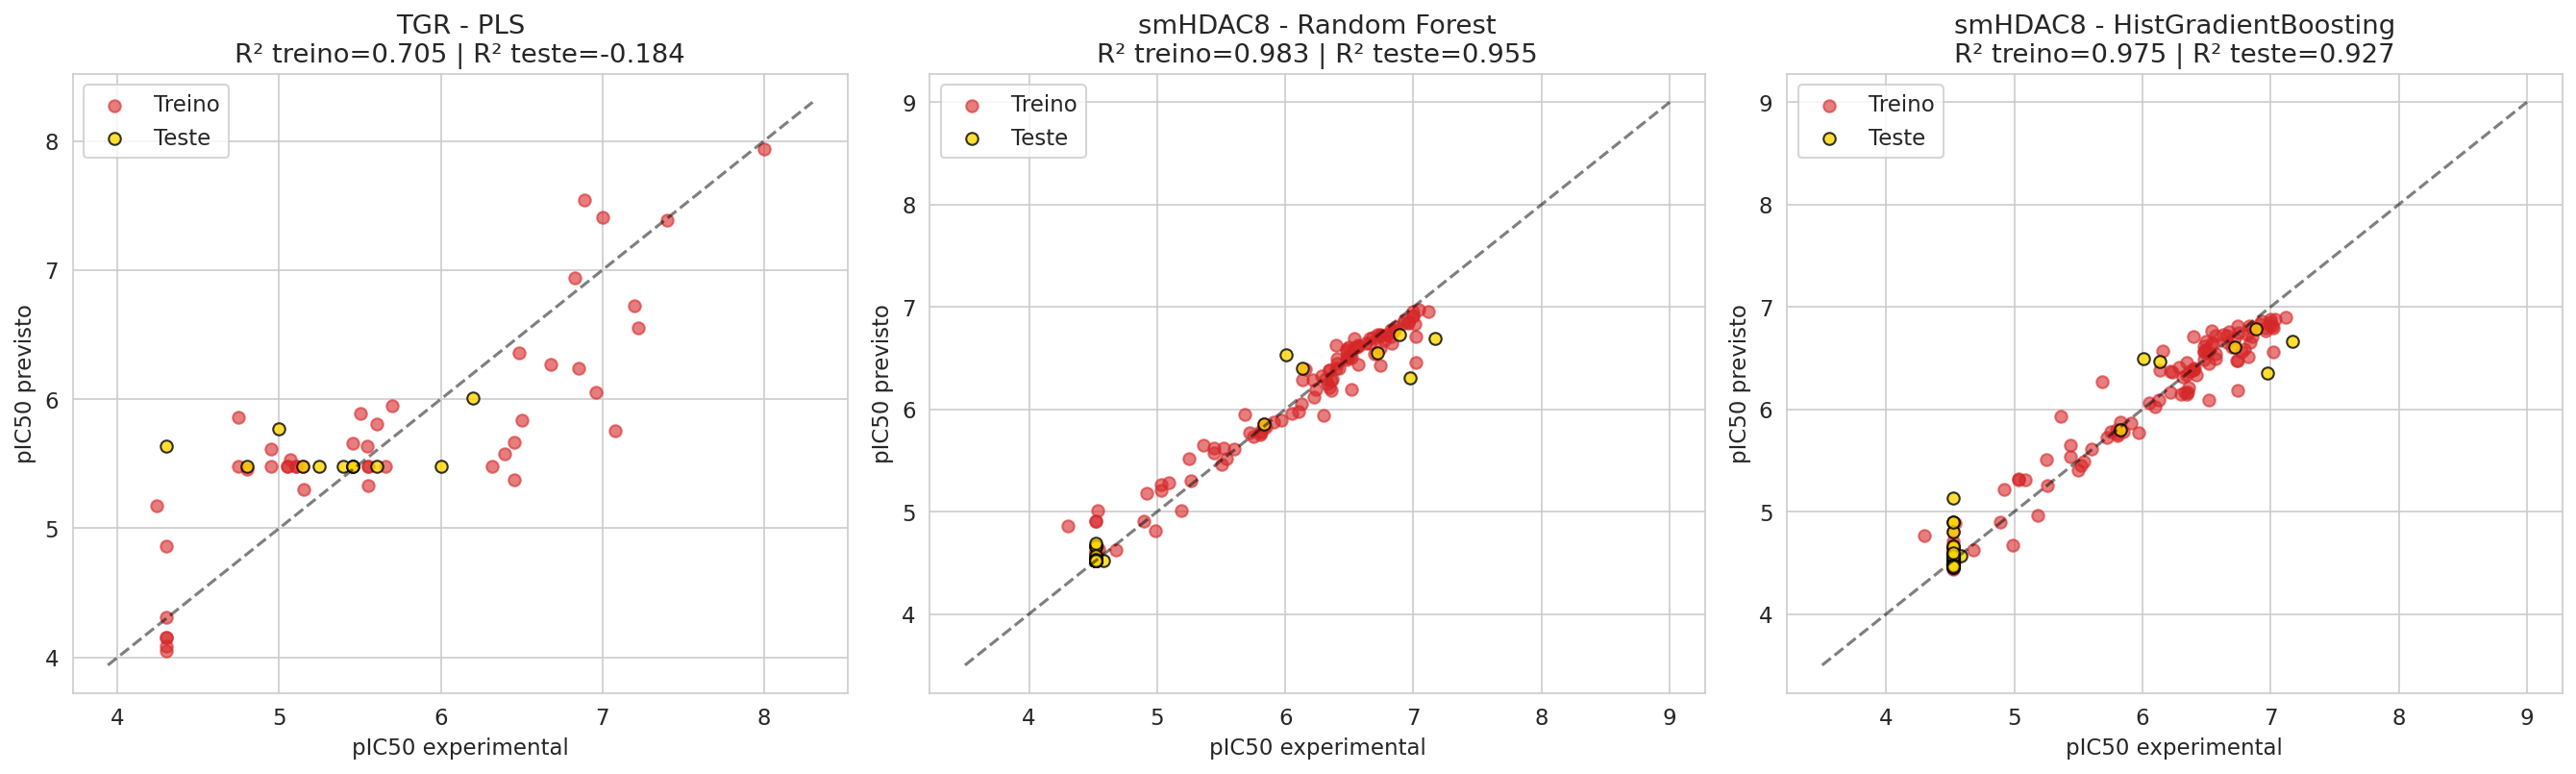

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# TGR
axes[0].scatter(y_tgr_train_vals, tgr_pred_train, alpha=0.6, label='Treino', color='#d62728')
axes[0].scatter(tgr_test['pIC50'].values, tgr_pred_test_final, alpha=0.8, label='Teste', color='gold', edgecolor='black')
lims = [min(y_tgr_train_vals.min(), tgr_test['pIC50'].min())-0.3, max(y_tgr_train_vals.max(), tgr_test['pIC50'].max())+0.3]
axes[0].plot(lims, lims, 'k--', alpha=0.5)
axes[0].set_xlabel('pIC50 experimental')
axes[0].set_ylabel('pIC50 previsto')
axes[0].set_title(f'TGR - PLS\nR² treino={tgr_r2_train:.3f} | R² teste={tgr_r2_test:.3f}')
axes[0].legend()

# smHDAC8 - RF
axes[1].scatter(y_hdac8_train_vals, hdac8_rf_pred_train, alpha=0.6, label='Treino', color='#d62728')
axes[1].scatter(hdac8_test['pIC50'].values, hdac8_rf_pred_test, alpha=0.8, label='Teste', color='gold', edgecolor='black')
lims2 = [3.5, 9]
axes[1].plot(lims2, lims2, 'k--', alpha=0.5)
axes[1].set_xlabel('pIC50 experimental')
axes[1].set_ylabel('pIC50 previsto')
axes[1].set_title(f'smHDAC8 - Random Forest\nR² treino={hdac8_rf_r2_train:.3f} | R² teste={hdac8_rf_r2_test:.3f}')
axes[1].legend()

# smHDAC8 - HGB
axes[2].scatter(y_hdac8_train_vals, hdac8_hgb_pred_train, alpha=0.6, label='Treino', color='#d62728')
axes[2].scatter(hdac8_test['pIC50'].values, hdac8_hgb_pred_test, alpha=0.8, label='Teste', color='gold', edgecolor='black')
axes[2].plot(lims2, lims2, 'k--', alpha=0.5)
axes[2].set_xlabel('pIC50 experimental')
axes[2].set_ylabel('pIC50 previsto')
axes[2].set_title(f'smHDAC8 - HistGradientBoosting\nR² treino={hdac8_hgb_r2_train:.3f} | R² teste={hdac8_hgb_r2_test:.3f}')
axes[2].legend()

plt.tight_layout()
plt.savefig('figuras/fig1_previsto_vs_experimental.png', bbox_inches='tight')
plt.show()

# Bloco 4 — Gráfico de resíduos (equivalente à Fig. 2 do artigo)

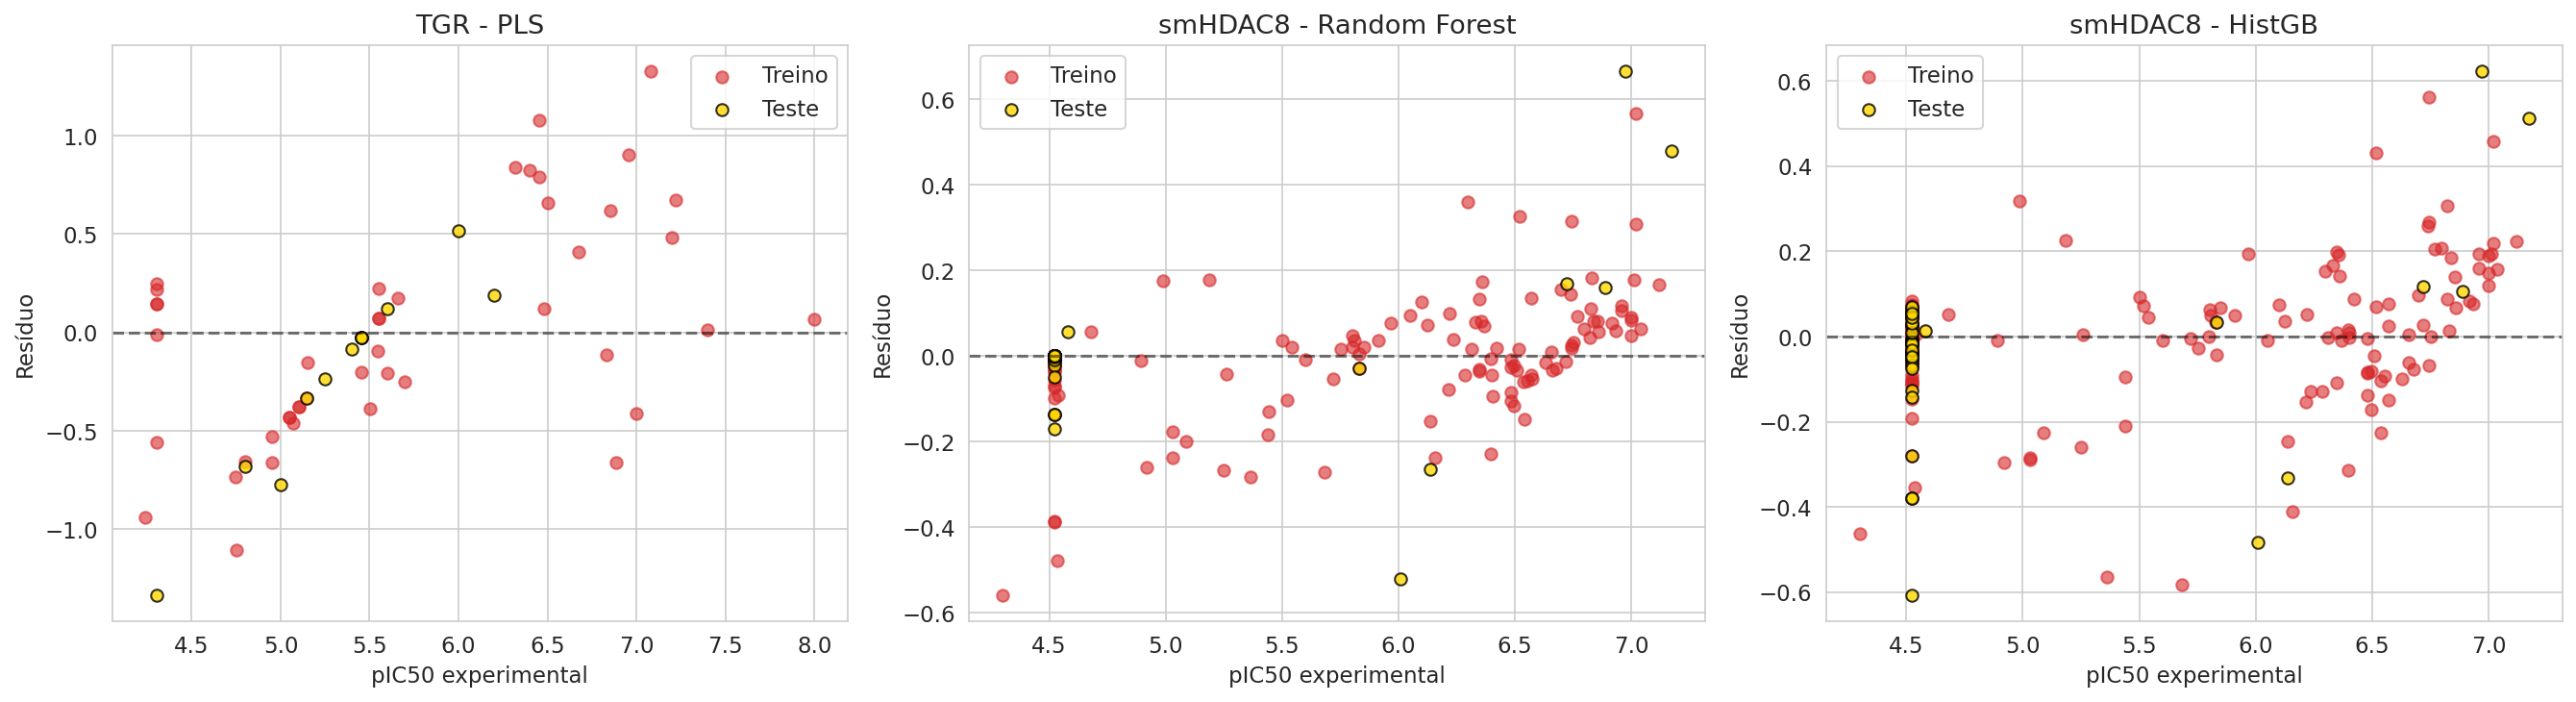

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

residuos_tgr_train = y_tgr_train_vals - tgr_pred_train
residuos_tgr_test = tgr_test['pIC50'].values - tgr_pred_test_final

axes[0].scatter(y_tgr_train_vals, residuos_tgr_train, alpha=0.6, label='Treino', color='#d62728')
axes[0].scatter(tgr_test['pIC50'].values, residuos_tgr_test, alpha=0.8, label='Teste', color='gold', edgecolor='black')
axes[0].axhline(0, color='black', linestyle='--', alpha=0.5)
axes[0].set_xlabel('pIC50 experimental')
axes[0].set_ylabel('Resíduo')
axes[0].set_title('TGR - PLS')
axes[0].legend()

residuos_rf_train = y_hdac8_train_vals - hdac8_rf_pred_train
residuos_rf_test = hdac8_test['pIC50'].values - hdac8_rf_pred_test

axes[1].scatter(y_hdac8_train_vals, residuos_rf_train, alpha=0.6, label='Treino', color='#d62728')
axes[1].scatter(hdac8_test['pIC50'].values, residuos_rf_test, alpha=0.8, label='Teste', color='gold', edgecolor='black')
axes[1].axhline(0, color='black', linestyle='--', alpha=0.5)
axes[1].set_xlabel('pIC50 experimental')
axes[1].set_ylabel('Resíduo')
axes[1].set_title('smHDAC8 - Random Forest')
axes[1].legend()

residuos_hgb_train = y_hdac8_train_vals - hdac8_hgb_pred_train
residuos_hgb_test = hdac8_test['pIC50'].values - hdac8_hgb_pred_test

axes[2].scatter(y_hdac8_train_vals, residuos_hgb_train, alpha=0.6, label='Treino', color='#d62728')
axes[2].scatter(hdac8_test['pIC50'].values, residuos_hgb_test, alpha=0.8, label='Teste', color='gold', edgecolor='black')
axes[2].axhline(0, color='black', linestyle='--', alpha=0.5)
axes[2].set_xlabel('pIC50 experimental')
axes[2].set_ylabel('Resíduo')
axes[2].set_title('smHDAC8 - HistGB')
axes[2].legend()

plt.tight_layout()
plt.savefig('figuras/fig2_residuos.png', bbox_inches='tight')
plt.show()

# Bloco 5 — Importância de features (Random Forest e HistGB, smHDAC8)

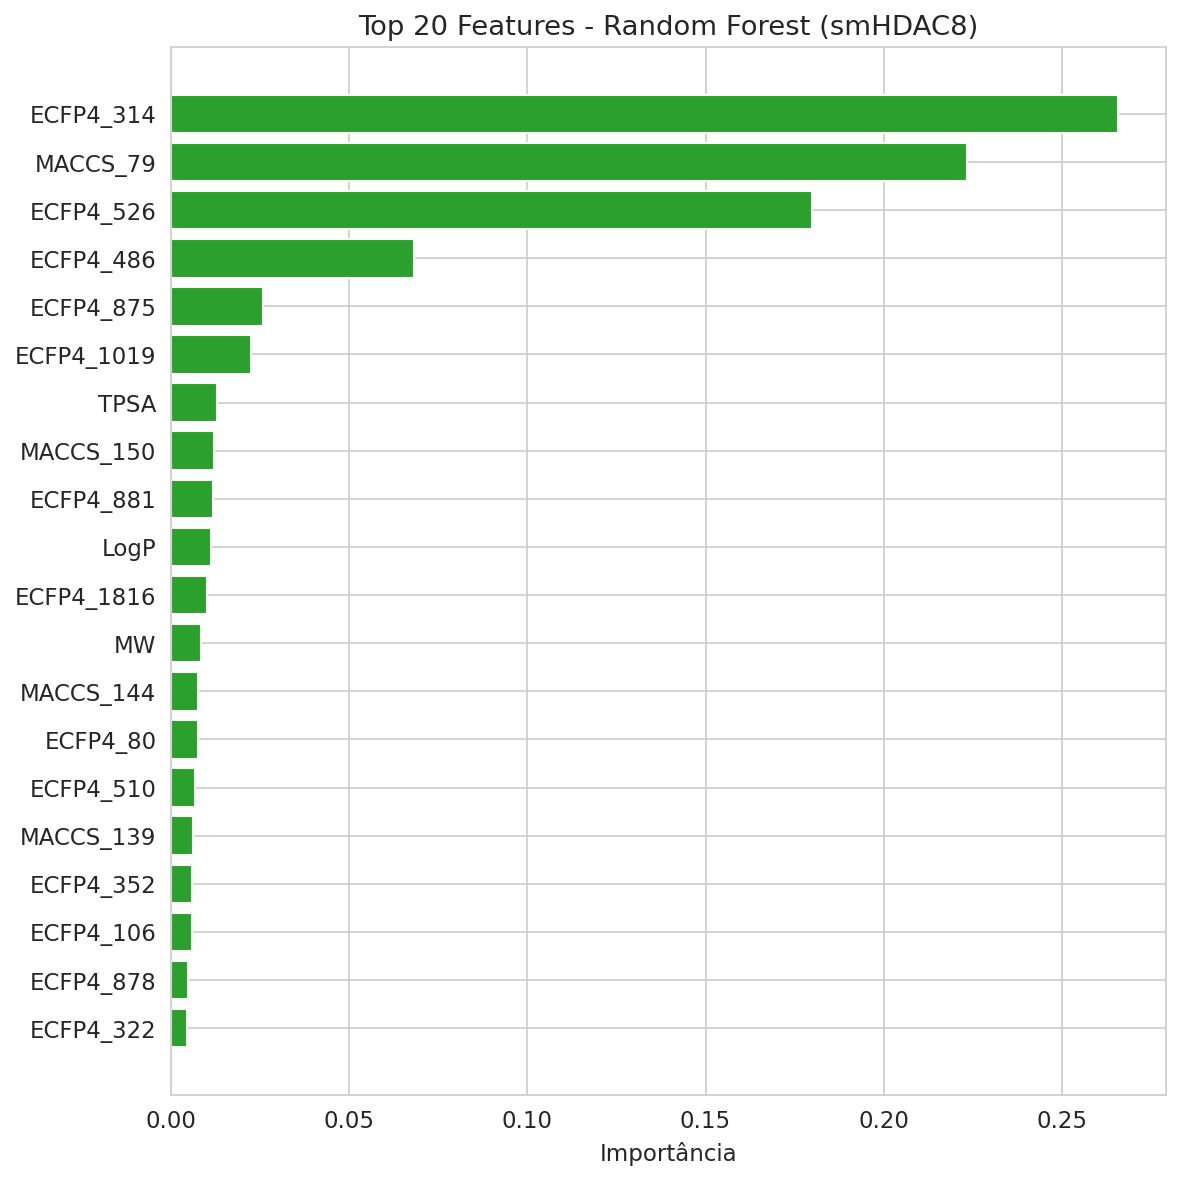

AttributeError: 'HistGradientBoostingRegressor' object has no attribute 'feature_importances_'

In [ ]:
def plot_feature_importance(model, feature_names, model_name, top_n=20):
    importances = model.feature_importances_
    idx = np.argsort(importances)[-top_n:]

    plt.figure(figsize=(8, 8))
    plt.barh(range(top_n), importances[idx], color='#2ca02c')
    plt.yticks(range(top_n), [feature_names[i] for i in idx])
    plt.xlabel('Importância')
    plt.title(f'Top {top_n} Features - {model_name} (smHDAC8)')
    plt.tight_layout()
    plt.savefig(f'figuras/fig3_importancia_{model_name.replace(" ", "_")}.png', bbox_inches='tight')
    plt.show()

plot_feature_importance(hdac8_rf_final, hdac8_features, 'Random Forest')
plot_feature_importance(hdac8_hgb_final, hdac8_features, 'HistGradientBoosting')

# Bloco 6 — Distribuição de pIC50 e classes de atividade

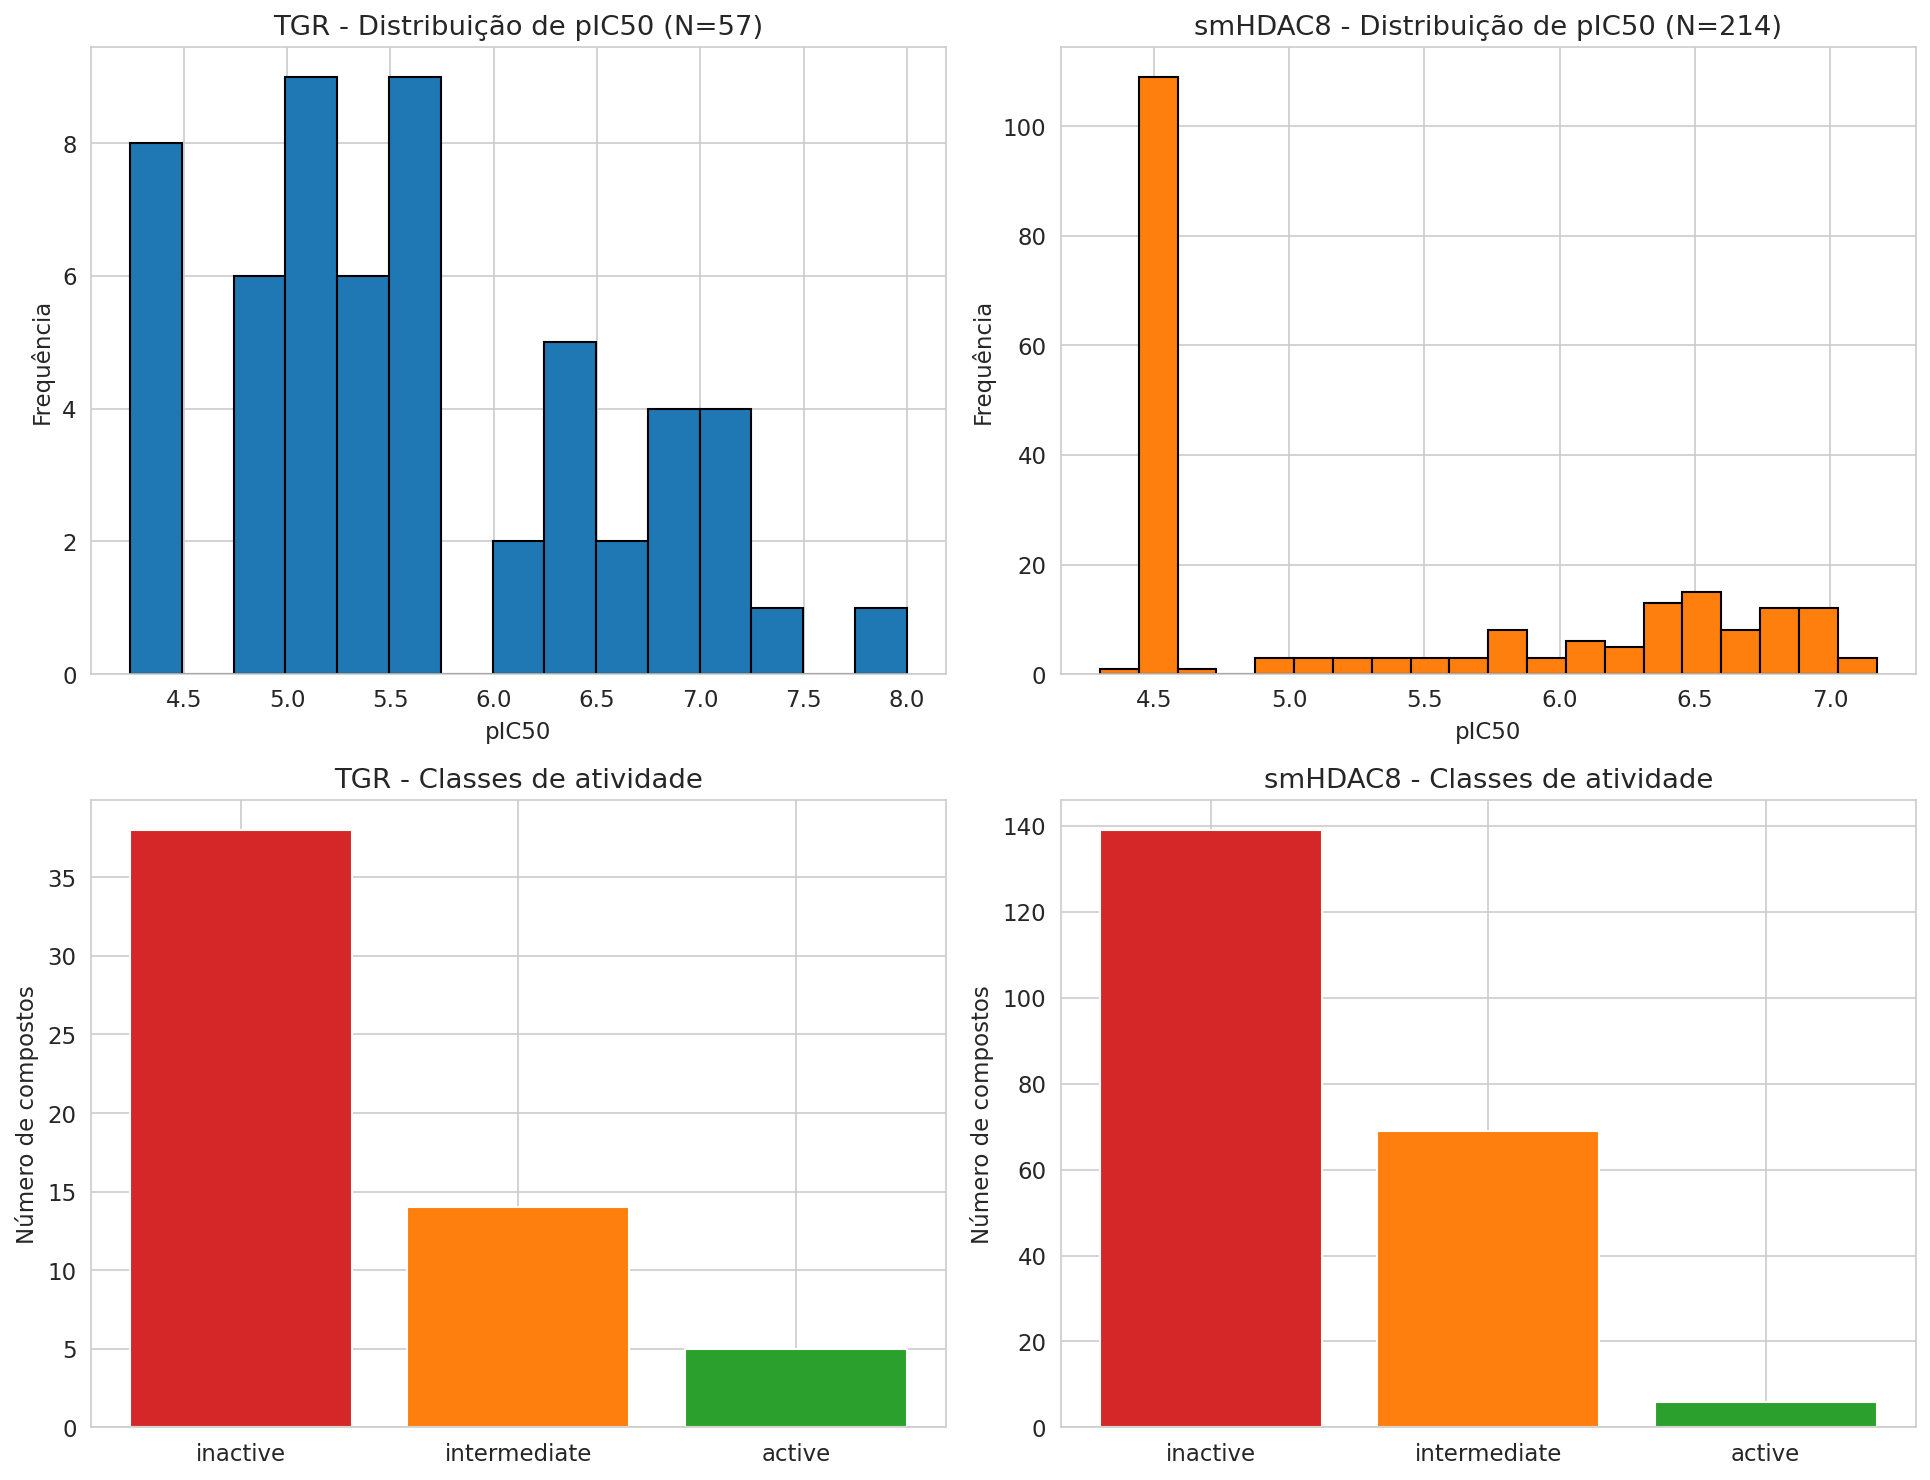

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0,0].hist(tgr_qsar['pIC50'], bins=15, color='#1f77b4', edgecolor='black')
axes[0,0].set_xlabel('pIC50')
axes[0,0].set_ylabel('Frequência')
axes[0,0].set_title('TGR - Distribuição de pIC50 (N=57)')

axes[0,1].hist(hdac8_qsar['pIC50'], bins=20, color='#ff7f0e', edgecolor='black')
axes[0,1].set_xlabel('pIC50')
axes[0,1].set_ylabel('Frequência')
axes[0,1].set_title('smHDAC8 - Distribuição de pIC50 (N=214)')

tgr_class_counts = tgr_qsar['activity_class'].value_counts()
axes[1,0].bar(tgr_class_counts.index, tgr_class_counts.values, color=['#d62728', '#ff7f0e', '#2ca02c'])
axes[1,0].set_ylabel('Número de compostos')
axes[1,0].set_title('TGR - Classes de atividade')

hdac8_class_counts = hdac8_qsar['activity_class'].value_counts()
axes[1,1].bar(hdac8_class_counts.index, hdac8_class_counts.values, color=['#d62728', '#ff7f0e', '#2ca02c'])
axes[1,1].set_ylabel('Número de compostos')
axes[1,1].set_title('smHDAC8 - Classes de atividade')

plt.tight_layout()
plt.savefig('figuras/fig4_distribuicao_atividade.png', bbox_inches='tight')
plt.show()

# Bloco 7 — Consenso RF vs HGB (smHDAC8) + candidatos do ZINC

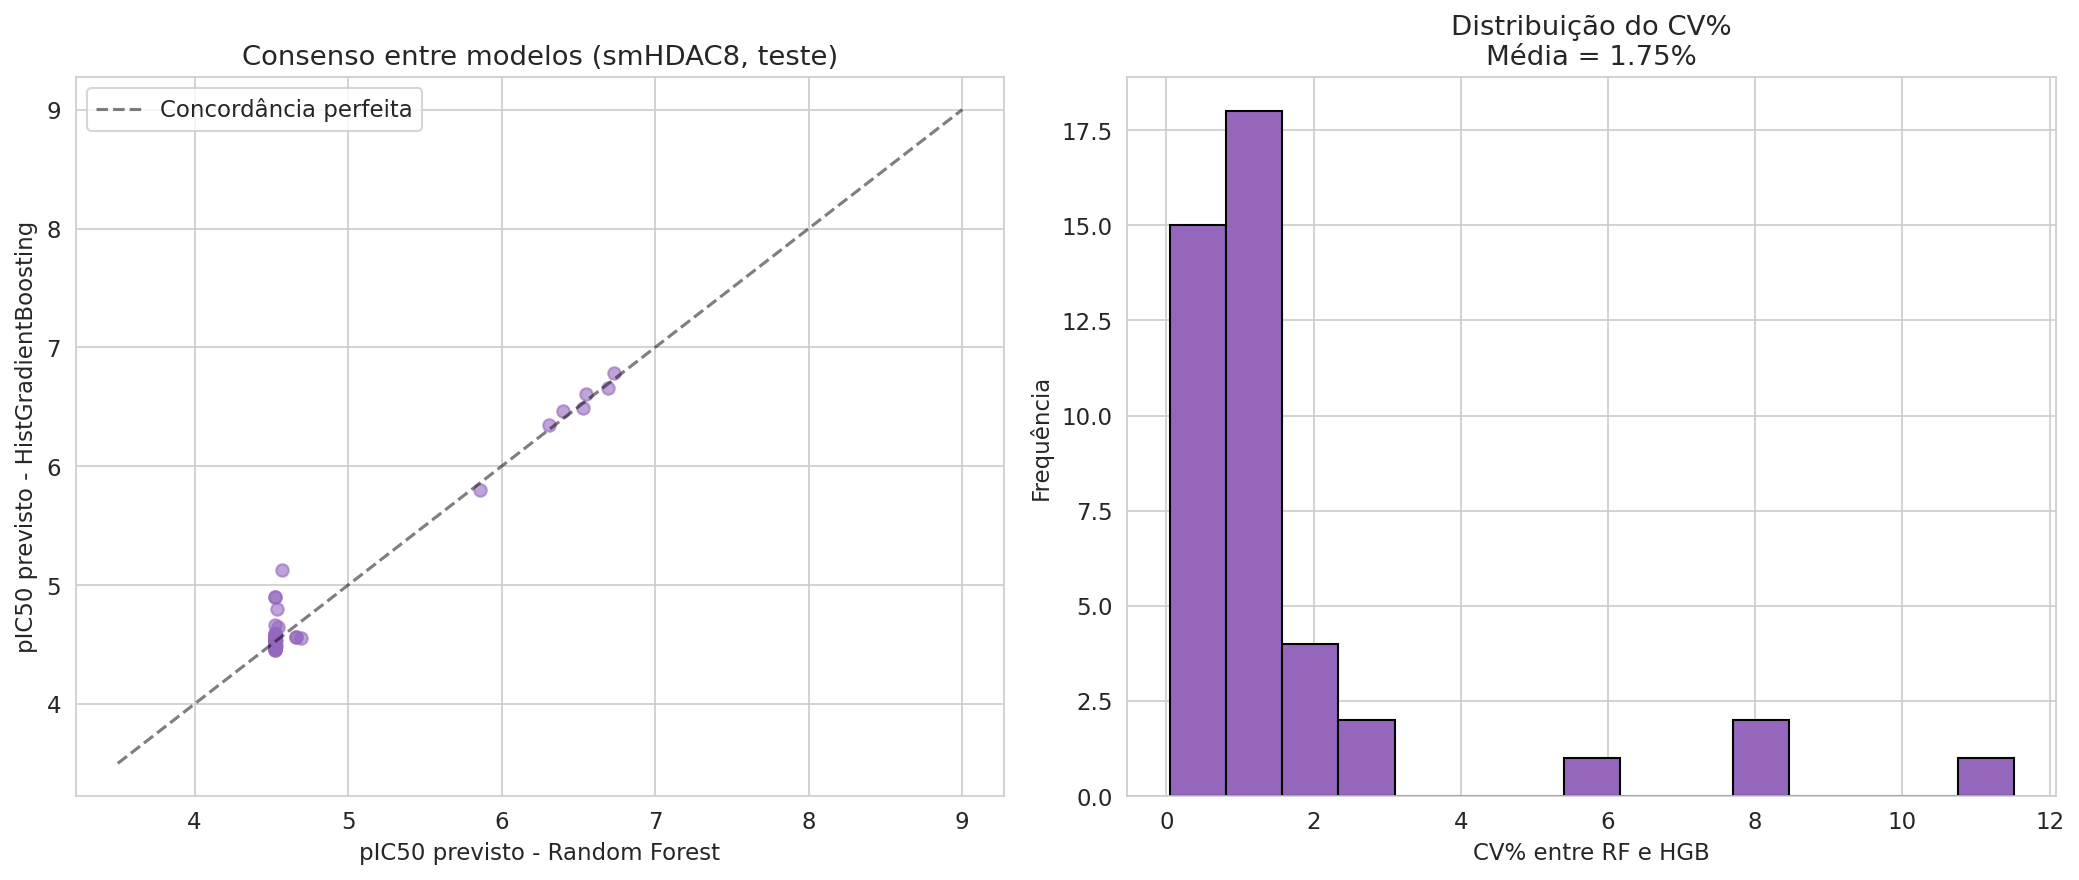

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Consenso: RF vs HGB no conjunto de teste
axes[0].scatter(hdac8_rf_pred_test, hdac8_hgb_pred_test, alpha=0.6, color='#9467bd')
lims3 = [3.5, 9]
axes[0].plot(lims3, lims3, 'k--', alpha=0.5, label='Concordância perfeita')
axes[0].set_xlabel('pIC50 previsto - Random Forest')
axes[0].set_ylabel('pIC50 previsto - HistGradientBoosting')
axes[0].set_title('Consenso entre modelos (smHDAC8, teste)')
axes[0].legend()

# CV% distribuição no teste
cv_test = np.abs(hdac8_rf_pred_test - hdac8_hgb_pred_test) / ((hdac8_rf_pred_test + hdac8_hgb_pred_test)/2) * 100
axes[1].hist(cv_test, bins=15, color='#9467bd', edgecolor='black')
axes[1].set_xlabel('CV% entre RF e HGB')
axes[1].set_ylabel('Frequência')
axes[1].set_title(f'Distribuição do CV%\nMédia = {cv_test.mean():.2f}%')

plt.tight_layout()
plt.savefig('figuras/fig5_consenso_RF_HGB.png', bbox_inches='tight')
plt.show()

# Bloco 8 — Top candidatos do ZINC (gráfico + tabela final)

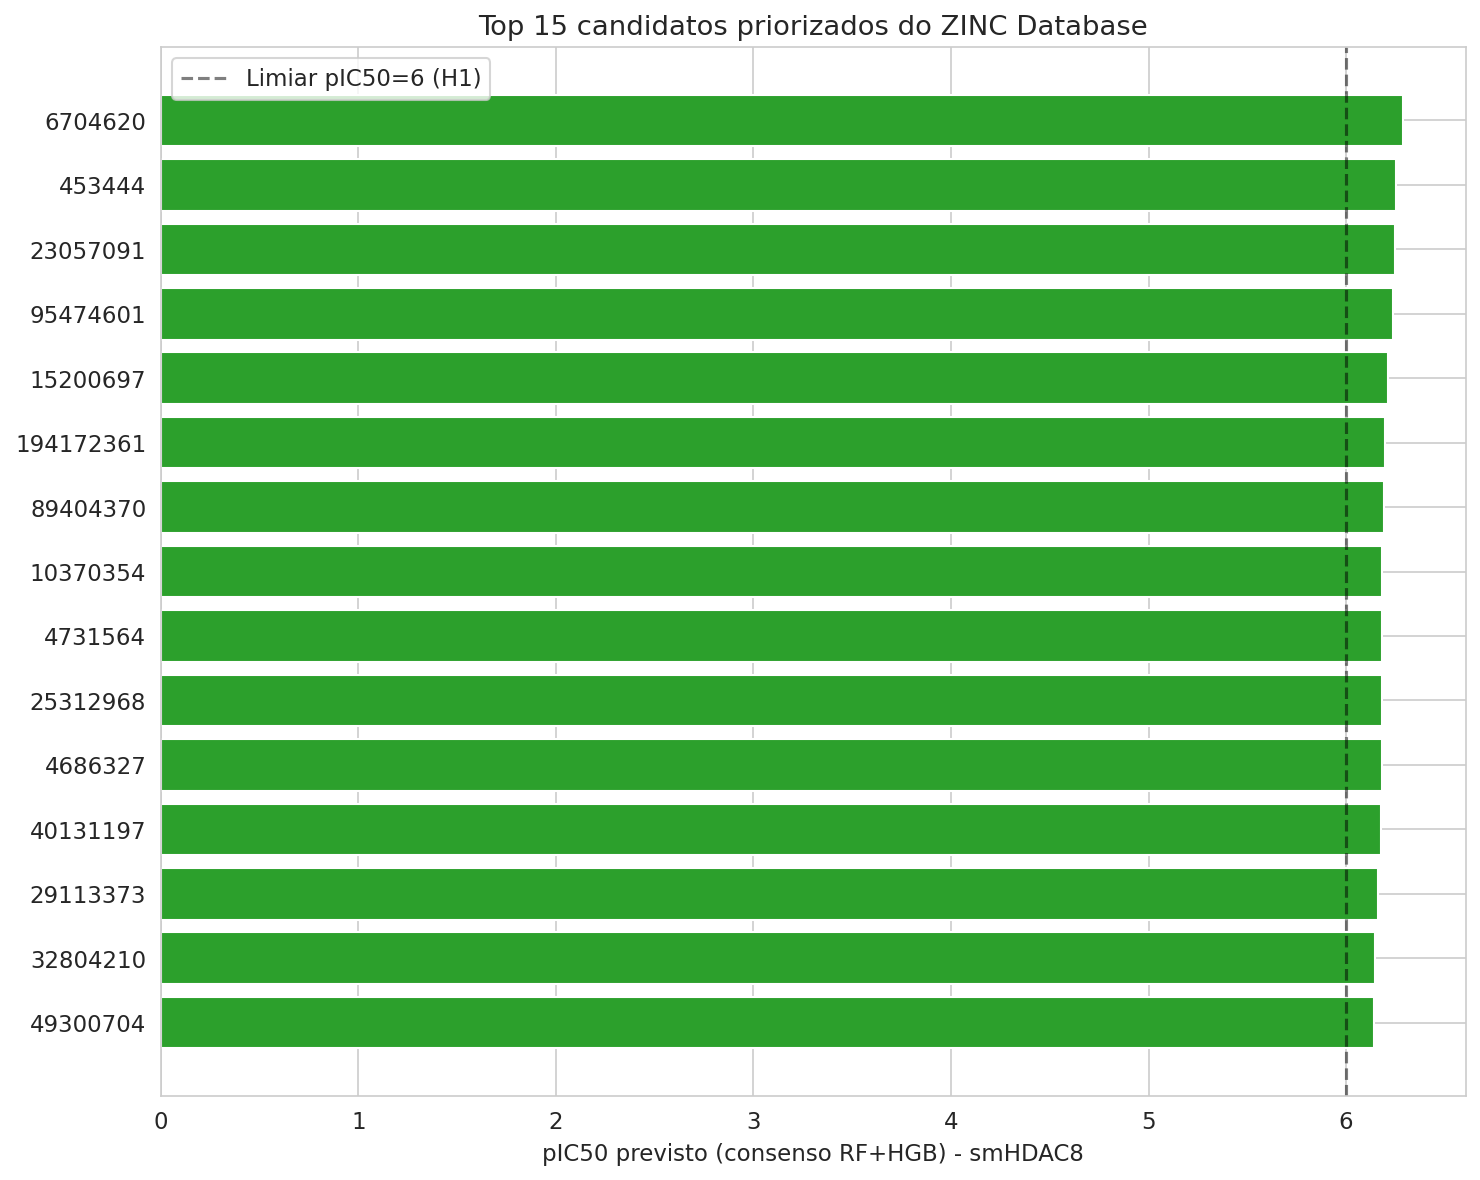

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

top15 = candidatos_limpos.head(15).sort_values('pIC50_HDAC8_mean')
colors = ['#2ca02c' if o == 'Tranche_InStock' else '#d62728' for o in top15['origem']]

ax.barh(range(len(top15)), top15['pIC50_HDAC8_mean'], color=colors)
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(top15['zinc_id'])
ax.set_xlabel('pIC50 previsto (consenso RF+HGB) - smHDAC8')
ax.set_title('Top 15 candidatos priorizados do ZINC Database')
ax.axvline(6.0, color='black', linestyle='--', alpha=0.5, label='Limiar pIC50=6 (H1)')
ax.legend()

plt.tight_layout()
plt.savefig('figuras/fig6_top_candidatos_zinc.png', bbox_inches='tight')
plt.show()

In [ ]:
# Tabela final consolidada com Lipinski + PAINS + origem
tabela_candidatos_final = candidatos_limpos.head(15)[
    ['zinc_id', 'origem', 'MW', 'LogP', 'pIC50_TGR', 'pIC50_HDAC8_mean', 'HDAC8_CV%']
].round(3)

print(tabela_candidatos_final.to_string(index=False))
tabela_candidatos_final.to_csv('tabelas/tabela2_top_candidatos.csv', index=False)

  zinc_id          origem      MW  LogP  pIC50_TGR  pIC50_HDAC8_mean  HDAC8_CV%
  6704620 Tranche_InStock 349.770 3.396      6.349             6.290      3.592
   453444 Tranche_InStock 329.381 3.338      6.550             6.252      2.808
 23057091 Tranche_InStock 443.912 4.491      6.256             6.250      3.382
 95474601 Tranche_InStock 337.379 3.398      5.281             6.238      3.083
 15200697 Tranche_InStock 342.323 3.208      6.168             6.212      2.470
194172361 Tranche_InStock 328.393 3.306      6.419             6.198      2.813
 89404370 Tranche_InStock 339.326 3.050      5.281             6.191      1.956
 10370354 Tranche_InStock 332.425 3.236      6.349             6.184      3.421
  4731564 Tranche_InStock 349.368 3.097      5.874             6.183      0.999
 25312968 Tranche_InStock 288.278 2.186      6.349             6.183      3.435
  4686327 Tranche_InStock 378.768 3.203      6.904             6.182      0.575
 40131197 Tranche_InStock 339.376 3.244 

Bloco 9 — Compactar tudo para download

In [ ]:
import shutil

shutil.make_archive('resultados_TCC', 'zip', '.', 'figuras')
shutil.make_archive('tabelas_TCC', 'zip', '.', 'tabelas')

print("Arquivos compactados: resultados_TCC.zip (figuras) e tabelas_TCC.zip (tabelas)")
print("\nBaixe pelo painel de arquivos do Colab (ícone de pasta à esquerda)")

Arquivos compactados: resultados_TCC.zip (figuras) e tabelas_TCC.zip (tabelas)

Baixe pelo painel de arquivos do Colab (ícone de pasta à esquerda)
